# Turbo codes: two weak codes that negotiate

In 1993 Berrou, Glavieux and Thitimajshima presented a code that worked within 0.5 dB of the Shannon limit. Until then, practical codes were thought to be stuck 3 dB or more away. The idea has two halves:

1. **Encoder**: two identical simple **recursive convolutional** encoders (RSC) encode the same block of $K$ bits. The first sees the bits in their original order, the second in an order shuffled by an **interleaver** $\Pi$. The systematic bits and both parity sequences are sent: $R\approx1/3$. Each encoder on its own is weak (8 states, small $d_\text{free}$). But a low-weight codeword has to be "light" for **both** of them at once, and the interleaver makes that rare.
2. **Decoder**: decoding the whole thing optimally is impossible (a trellis with $2^K$ states). Instead, each encoder is decoded **optimally on its own** with the BCJR algorithm (MAP on the trellis), and the two decoders take turns passing each other **extrinsic** information about the bits:
$$L_\text{post}=\underbrace{L_\text{ch}}_{\text{channel}}+\underbrace{L_a}_{\text{from the neighbour}}+\underbrace{L_e}_{\text{new: from its own parity}},\qquad\text{only }L_e\text{ is passed on.}$$
It is the same principle as BP for LDPC (the LDPC notebook), except that there are only two "check nodes", and each one is a whole convolutional code.

LTE (36.212 §5.1.3) encodes all data with a turbo code using $g_0=13_8$, $g_1=15_8$ and a QPP interleaver; 5G NR replaced it with LDPC. Here we go through it step by step, then put a $K=1024$ code to work.

**How this notebook is organized.**
- *Part I: the machinery step by step* (sections 1–7). Why the encoder is recursive, the trellis and the tail, the turbo encoder and the interleaver (and why it decides everything), a derivation of BCJR checked against brute force, $\max^*$ and max-log, extrinsic information and the "echo", and turbo iterations by hand on a 40-bit block.
- *Part II: $K=1024$ at work* (sections 8–13). Iterations from the inside, the EXIT chart and threshold, the BER/FER waterfall, the role of the interleaver, block length, and a comparison with LDPC.

All parameters are in the cell below; everything else is recomputed from them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc
from scipy.integrate import quad
from scipy.optimize import brentq

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
K_TURBO = 1024     # block length (QPP defined for 40, 512, 1024, 2048, 6144)
ITERS = 8          # full iterations (each is two BCJR runs)
EBN0_DB = 0.5      # operating point for sections 5–9 (R=1/3 waterfall at K=1024 is 0.25…1 dB)
SCALE_ML = 0.7     # extrinsic scaling for max-log-MAP

rng = np.random.default_rng(SEED)

## Primitives: QPP, RSC and trellis, turbo encoder, BCJR, turbo decoder, channel, J-function
| function | what it does | section |
|---|---|---|
| `NXT`, `PAR`, `FB`, `PREV_S/U` | RSC trellis tables: next state, parity bit, tail input, edges into a state | 1, 2 |
| `rsc_encode`, `turbo_encode` | RSC with termination; parallel concatenation through $\Pi$ | 2, 3 |
| `qpp` | interleaver $\Pi(i)=(f_1i+f_2i^2)\bmod K$ | 3 |
| `bcjr`, `maxstar` | MAP decoder of one RSC: log-MAP / max-log-MAP | 4, 5 |
| `turbo_decode` | extrinsic exchange, early stopping, `extrinsic` flag | 6–13 |
| `channel`, `puncture_half` | BPSK + AWGN → LLR, puncturing to $R\approx1/2$ | 4, 13 |
| `mi`, `J`, `biawgn_limit` | mutual information, EXIT, Shannon limit | 9, 10 |

In [2]:
# ---------- QPP interleaver (36.212, table 5.1.3-3) ----------
QPP = {40: (3, 10), 512: (31, 64), 1024: (31, 64), 2048: (31, 64), 6144: (263, 480)}

def qpp(K):
    """Quadratic permutation polynomial interleaver Π(i) = (f1·i + f2·i²) mod K."""
    f1, f2 = QPP[K]
    i = np.arange(K, dtype=np.int64)
    return (f1 * i + f2 * i * i) % K

# ---------- RSC: G(D) = [1, g1/g0], g0 = 1+D²+D³ (13₈) is the feedback, g1 = 1+D+D³ (15₈) ----------
NXT = np.zeros((8, 2), int); PAR = np.zeros((8, 2), int); FB = np.zeros(8, int)
for s in range(8):
    s1, s2, s3 = (s >> 2) & 1, (s >> 1) & 1, s & 1          # state = register contents (s1 is the newest)
    FB[s] = s2 ^ s3                                           # input that cancels the feedback → tail
    for u in (0, 1):
        a = u ^ s2 ^ s3                                       # bit shifted into the register
        NXT[s, u] = (a << 2) | (s1 << 1) | s2
        PAR[s, u] = a ^ s1 ^ s3
PREV_S = np.zeros((8, 2), int); PREV_U = np.zeros((8, 2), int)   # exactly 2 edges enter every state
_c = np.zeros(8, int)
for s in range(8):
    for u in (0, 1):
        ns = NXT[s, u]; PREV_S[ns, _c[ns]] = s; PREV_U[ns, _c[ns]] = u; _c[ns] += 1

def rsc_encode(u):
    """u (B,K) → parity z (B,K), tail: systematic xt (B,3) and parity zt (B,3)."""
    B, K = u.shape
    s = np.zeros(B, int); z = np.empty((B, K), int)
    for k in range(K):
        z[:, k] = PAR[s, u[:, k]]; s = NXT[s, u[:, k]]
    xt = np.empty((B, 3), int); zt = np.empty((B, 3), int)
    for k in range(3):                                        # terminate in the zero state
        ut = FB[s]; xt[:, k] = ut; zt[:, k] = PAR[s, ut]; s = NXT[s, ut]
    return z, xt, zt

def turbo_encode(u, pi=None):
    """u (B,K) → (B, 3K+12): triples [systematic, parity 1, parity 2] and 12 tail bits. R ≈ 1/3."""
    pi = qpp(u.shape[1]) if pi is None else pi
    z1, xt1, zt1 = rsc_encode(u)
    z2, xt2, zt2 = rsc_encode(u[:, pi])
    return np.concatenate([np.stack([u, z1, z2], -1).reshape(len(u), -1), xt1, zt1, xt2, zt2], 1)

def maxstar(a, b, exact=True):
    """max*(a,b) = ln(eᵃ + eᵇ) = max(a,b) + ln(1 + e^−|a−b|); max-log drops the correction."""
    m = np.maximum(a, b)
    return m + np.log1p(np.exp(-np.abs(a - b))) if exact else m

def bcjr(Ls, Lp, La, Lst, Lpt, exact=True, trace=None):
    """MAP decoder of the RSC (log-MAP or max-log-MAP) on the terminated trellis. LLR = ln P(0)/P(1), (B,K).
    trace is a dict that receives γ, α, β (for the step-by-step walkthrough)."""
    B, K = Ls.shape
    Lx = np.concatenate([Ls + La, Lst], 1).T; Lz = np.concatenate([Lp, Lpt], 1).T
    zs = 1 - 2 * PAR; xs = np.array([1, -1])
    g = 0.5 * (Lx[:, :, None, None] * xs + Lz[:, :, None, None] * zs)     # γ_t(s,u): (T,B,8,2)
    T = K + 3
    al = np.full((T + 1, B, 8), -1e9); al[0, :, 0] = 0                    # start in zero
    for t in range(T):
        a = maxstar(al[t][:, PREV_S[:, 0]] + g[t][:, PREV_S[:, 0], PREV_U[:, 0]],
                    al[t][:, PREV_S[:, 1]] + g[t][:, PREV_S[:, 1], PREV_U[:, 1]], exact)
        al[t + 1] = a - a.max(1, keepdims=True)                           # normalize: only differences matter
    be = np.full((B, 8), -1e9); be[:, 0] = 0                              # end in zero (tail)
    bes = np.empty((T + 1, B, 8)); bes[T] = be
    Lout = np.empty((B, K))
    red = (lambda v: np.logaddexp.reduce(v, 1)) if exact else (lambda v: v.max(1))
    for t in range(T - 1, -1, -1):
        if t < K:
            m = al[t][:, :, None] + g[t] + be[:, NXT]                     # α_t(s) + γ_t(s,u) + β_{t+1}(s')
            Lout[:, t] = red(m[:, :, 0]) - red(m[:, :, 1])
        b = maxstar(be[:, NXT[:, 0]] + g[t][:, :, 0], be[:, NXT[:, 1]] + g[t][:, :, 1], exact)
        be = b - b.max(1, keepdims=True); bes[t] = be
    if trace is not None:
        trace.update(g=g, al=al, be=bes)
    return Lout

def turbo_decode(L, K, iters=ITERS, exact=True, scale=SCALE_ML, cb=None, pi=None, extrinsic=True, early=True):
    """Iterative decoder: two BCJRs exchange extrinsic information through the interleaver.
    Returns decisions (B,K) and the iteration count per frame. Early stopping: a frame is frozen
    once the hard decisions of both decoders agree.
    cb(it, d) receives a dict of this iteration's LLRs (all in natural bit order).
    extrinsic=False is a deliberate bug: the neighbour gets the posterior LLR without its own contribution removed."""
    B = len(L)
    m = L[:, :3 * K].reshape(-1, K, 3); t = L[:, 3 * K:]
    Ls, Lp1, Lp2 = m[..., 0], m[..., 1], m[..., 2]
    pi = qpp(K) if pi is None else pi
    ipi = np.argsort(pi)
    sc = 1.0 if exact else scale
    A1, L1, Le1, L2, Le2 = (np.zeros((B, K)) for _ in range(5))
    n_it = np.full(B, iters); act = np.arange(B)
    for it in range(iters):
        a = act
        l1 = bcjr(Ls[a], Lp1[a], Le2[a], t[a, 0:3], t[a, 3:6], exact)           # a priori of decoder 1 = extrinsic from 2
        le1 = sc * (l1 - Ls[a] - Le2[a]) if extrinsic else l1 - Ls[a]
        l2 = bcjr(Ls[a][:, pi], Lp2[a], le1[:, pi], t[a, 6:9], t[a, 9:12], exact)   # decoder 2 works in Π order
        le2 = sc * (l2 - Ls[a][:, pi] - le1[:, pi]) if extrinsic else l2 - Ls[a][:, pi]
        A1[a], L1[a], Le1[a], L2[a], Le2[a] = Le2[a], l1, le1, l2[:, ipi], le2[:, ipi]
        if cb: cb(it, dict(La1=A1, L1=L1, Le1=Le1, L2=L2, Le2=Le2))
        if early:
            done = ((l1 < 0) == (L2[a] < 0)).all(1)
            n_it[a[done]] = it + 1; act = a[~done]
            if len(act) == 0: break
    return (L2 < 0).astype(int), n_it

def channel(c, ebn0_db, R, rng, mask=None):
    """BPSK + AWGN → LLR 2y/σ². mask marks transmitted bits (punctured ones get LLR = 0)."""
    s2 = 1 / (2 * R * 10 ** (ebn0_db / 10))
    L = 2 * ((1 - 2.0 * c) + np.sqrt(s2) * rng.standard_normal(c.shape)) / s2
    if mask is not None: L[:, ~mask] = 0
    return L

def puncture_half(K):
    """Mask for R≈1/2: every other parity bit of each encoder is punctured."""
    m = np.ones((K, 3), bool); m[1::2, 1] = False; m[0::2, 2] = False
    return np.r_[m.ravel(), np.ones(12, bool)]

def mi(L, x):
    """Mutual information between an LLR and a bit x∈{±1}: I = 1 − E[log2(1 + e^{−xL})]."""
    return 1 - np.mean(np.logaddexp(0, -x * L)) / np.log(2)

# J(σ): information carried by a Gaussian LLR ~ N(σ²/2, σ²)
_t, _w = np.polynomial.hermite.hermgauss(120)
_S = np.linspace(0, 25, 5001)
_J = np.maximum.accumulate([1 - np.sum(_w * np.logaddexp(0, -(s * s / 2 + np.sqrt(2) * s * _t))) / np.sqrt(np.pi) / np.log(2) for s in _S])
J = lambda s: np.interp(s, _S, _J)
Jinv = lambda I: np.interp(I, _J, _S)

def biawgn_limit(R):
    """Eb/N0 (dB) at which the BPSK-AWGN capacity equals R."""
    return brentq(lambda e: J(np.sqrt(8 * R * 10 ** (e / 10))) - R, -3, 10)

# self-checks
assert all(len(np.unique(qpp(K))) == K for K in QPP), "QPP is not a permutation"
_u = rng.integers(0, 2, (4, 40)); _c = turbo_encode(_u)
assert np.all(turbo_decode(4.0 * (1 - 2 * _c), 40)[0] == _u)
R3 = K_TURBO / (3 * K_TURBO + 12)
print(f"K = {K_TURBO}, n = {3 * K_TURBO + 12}, R = {R3:.4f}; Shannon for BPSK at R = 1/3: {biawgn_limit(1/3):.2f} dB, at R = 1/2: {biawgn_limit(1/2):.2f} dB")

K = 1024, n = 3084, R = 0.3320; Shannon for BPSK at R = 1/3: -0.50 dB, at R = 1/2: 0.19 dB


# Part I. The machinery step by step

## 1. Convolutional codes: why recursive
A convolutional encoder is a shift register of $\nu=3$ cells (8 states) plus XORs. It is convenient to write it with polynomials in the delay $D$:
- **non-recursive** (NSC): outputs $y_j(D)=u(D)\,g_j(D)$, i.e. FIR filters over GF(2). A single 1 at the input produces an output of length $\nu+1$, a **finite** response;
- **recursive systematic** (RSC, LTE): $x=u$, parity $z(D)=u(D)\,\dfrac{g_1(D)}{g_0(D)}$, $g_0=1+D^2+D^3$ (feedback), $g_1=1+D+D^3$. Dividing by $g_0$ is an IIR filter: the response to a single 1 is **infinite** and periodic. $g_0$ is a primitive polynomial of degree 3, so the period is $2^3-1=7$.

**Why it matters.** A weight-1 input to an RSC produces parity of infinite weight (huge, within a block). Only inputs divisible by $g_0$ give a finite response, and the lightest of them is $1+D^7$ (two ones 7 apart, since $g_0\,|\,1+D^7$). So low-weight RSC codewords come from inputs of **weight ≥ 2 with a special structure**. The interleaver destroys that structure for the second encoder (section 3). With an NSC, any low-weight input gives low weight, and an interleaver would not help.

Left: impulse responses. Middle: RSC parity for the input $1+D^d$. Right: parity weight (in a 64-bit window, no termination).

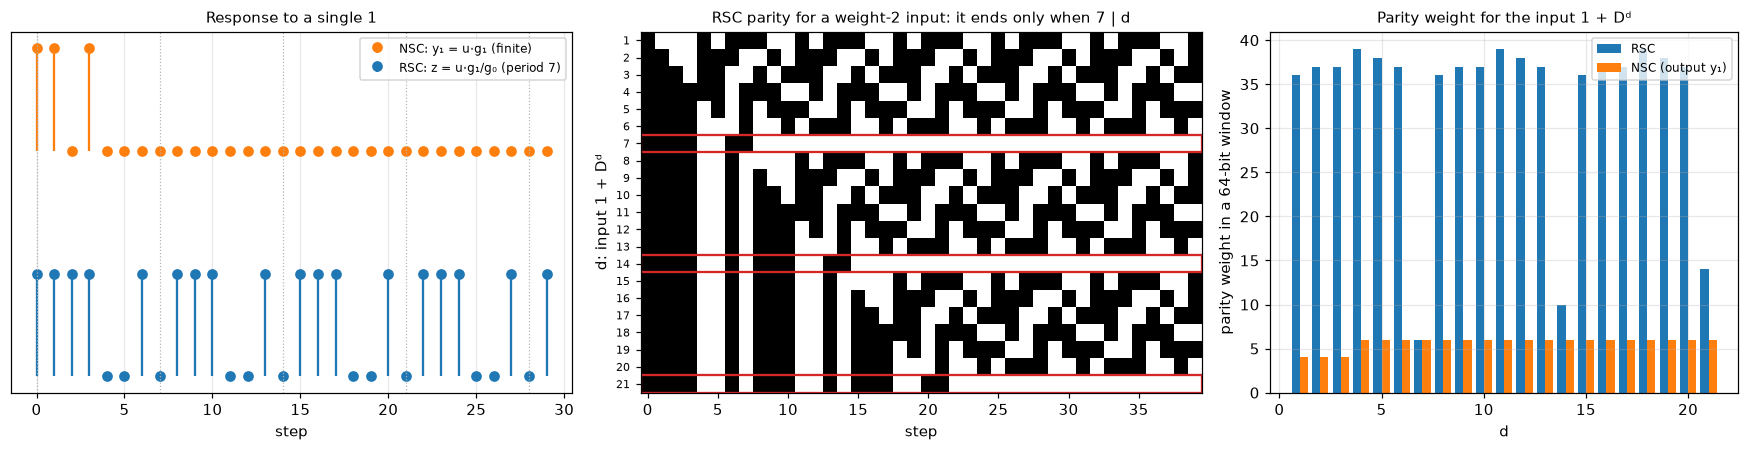

RSC response to 1:  1111001011100101110010 … period 7
(1 + D⁷) mod g₀ = [0, 0, 0] → g₀ divides 1 + D⁷;  (1 + D⁵) mod g₀ = [0, 1, 0]
RSC parity weight for 1 + D⁷: 6, for 1 + D⁵: 38 (and growing with the window length)


In [3]:
def nsc_encode(u, taps=([1, 0, 1, 1], [1, 1, 0, 1])):
    # non-recursive (13₈, 15₈): two FIR filters over GF(2); coefficients of D⁰..D³
    return [np.array([np.convolve(r, t)[:u.shape[1]] % 2 for r in u]) for t in taps]

Lw = 64
imp = np.zeros((1, Lw), int); imp[0, 0] = 1
y0, y1 = nsc_encode(imp)
z_imp = rsc_encode(imp)[0][0]
ds = np.arange(1, 22)
U2 = np.zeros((len(ds), Lw), int); U2[:, 0] = 1; U2[np.arange(len(ds)), ds] = 1
Z2 = rsc_encode(U2)[0]
w_nsc = nsc_encode(U2)[1].sum(1)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
n_show = 30
ax[0].stem(np.arange(n_show), y1[0, :n_show] + 2.2, linefmt="C1-", markerfmt="C1o", basefmt=" ", bottom=2.2, label="NSC: y₁ = u·g₁ (finite)")
ax[0].stem(np.arange(n_show), z_imp[:n_show], linefmt="C0-", markerfmt="C0o", basefmt=" ", label="RSC: z = u·g₁/g₀ (period 7)")
for k in range(0, n_show, 7): ax[0].axvline(k, color="0.7", ls=":", lw=0.8)
ax[0].set_yticks([]); ax[0].set_xlabel("step"); ax[0].legend(fontsize=8, loc="upper right"); ax[0].set_title("Response to a single 1", fontsize=10)
ax[1].imshow(Z2[:, :40], cmap="Greys", aspect="auto", interpolation="nearest"); ax[1].grid(False)
ax[1].set_yticks(range(len(ds))); ax[1].set_yticklabels(ds, fontsize=7); ax[1].set_ylabel("d: input 1 + Dᵈ"); ax[1].set_xlabel("step")
for d in (7, 14, 21): ax[1].add_patch(plt.Rectangle((-0.5, d - 1.5), 40, 1, fill=False, ec="C3", lw=1.5))
ax[1].set_title("RSC parity for a weight-2 input: it ends only when 7 | d", fontsize=10)
ax[2].bar(ds - 0.2, Z2.sum(1), 0.4, color="C0", label="RSC")
ax[2].bar(ds + 0.2, w_nsc, 0.4, color="C1", label="NSC (output y₁)")
ax[2].set_xlabel("d"); ax[2].set_ylabel(f"parity weight in a {Lw}-bit window"); ax[2].legend(fontsize=8); ax[2].set_title("Parity weight for the input 1 + Dᵈ", fontsize=10)
plt.tight_layout(); plt.show()

def gf2_mod(a, b):                                # remainder of polynomial division over GF(2), coefficients from D⁰
    a = list(a)
    while len(a) >= len(b):
        if a[-1]:
            for i in range(len(b)): a[len(a) - len(b) + i] ^= b[i]
        a.pop()
    return a
print("RSC response to 1: ", "".join(map(str, z_imp[:22])), "… period", next(p for p in range(1, 20) if np.array_equal(z_imp[10:30], z_imp[10 + p:30 + p])))
print("(1 + D⁷) mod g₀ =", gf2_mod([1, 0, 0, 0, 0, 0, 0, 1], [1, 0, 1, 1]), "→ g₀ divides 1 + D⁷;  (1 + D⁵) mod g₀ =", gf2_mod([1, 0, 0, 0, 0, 1], [1, 0, 1, 1]))
print(f"RSC parity weight for 1 + D⁷: {Z2[6].sum()}, for 1 + D⁵: {Z2[4].sum()} (and growing with the window length)")

## 2. The trellis and termination
The encoder state $s=(s_1s_2s_3)$ is the register contents, $2^3=8$ states. At every step the input $u$ moves $s\to s'$ and emits a parity bit $z$:
$$a=u\oplus s_2\oplus s_3\ (\text{feedback }g_0),\qquad s'=(a,\,s_1,\,s_2),\qquad z=a\oplus s_1\oplus s_3\ (g_1).$$
Unrolling the transitions in time gives the **trellis**: every path starting from state 0 is one codeword, and exactly two edges leave and two edges enter every state (`NXT`, `PREV_S`). The BCJR decoder is a forward and a backward pass over this trellis.

**Termination.** So that the trellis ends in the known state 0, 3 **tail** bits are fed in after the data. For a recursive encoder these are not zeros: the feedback has to be cancelled, $u=s_2\oplus s_3$ (the `FB` table), so that $a=0$ and the register clears in 3 steps. Tail bits are not data, but they are transmitted (3 systematic and 3 parity per encoder); otherwise the last bits of the block would be less protected.

Below: the trellis and the path for the input `1 0 1 1 0 0 1 0` plus the tail. Solid edges are $u=0$, dashed edges are $u=1$; labels on the path are $u/z$.

 s  (s1s2s3) | u=0: s' z | u=1: s' z | tail u
 0   000      |    0  0  |    4  1  |   0
 1   001      |    4  0  |    0  1  |   1
 2   010      |    5  1  |    1  0  |   1
 3   011      |    1  1  |    5  0  |   0
 4   100      |    2  1  |    6  0  |   0
 5   101      |    6  1  |    2  0  |   1
 6   110      |    7  0  |    3  1  |   1
 7   111      |    3  0  |    7  1  |   0


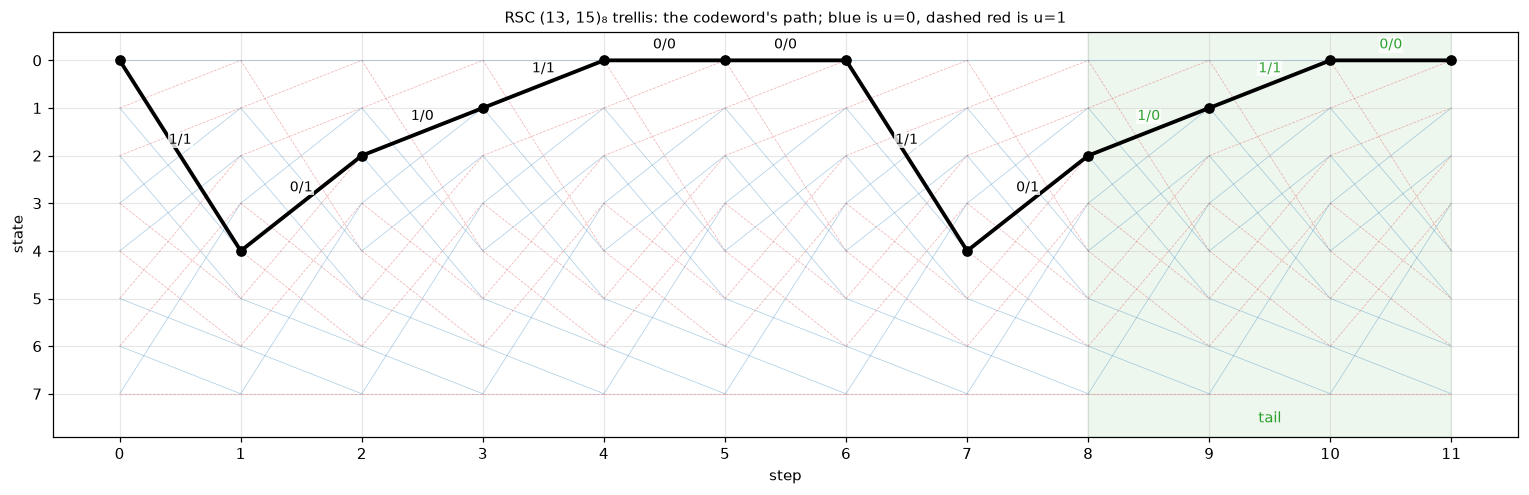


data [1 0 1 1 0 0 1 0] → parity [1 1 0 1 0 0 1 1]; tail: u = [1 1 0], z = [0 1 0]; final state 0
rsc_encode: z = [1 1 0 1 0 0 1 1], tail x = [1 1 0], z = [0 1 0]; matches: True


In [4]:
print(" s  (s1s2s3) | u=0: s' z | u=1: s' z | tail u")
for s in range(8):
    print(f" {s}   {s >> 2 & 1}{s >> 1 & 1}{s & 1}      |    {NXT[s, 0]}  {PAR[s, 0]}  |    {NXT[s, 1]}  {PAR[s, 1]}  |   {FB[s]}")

u_ex = np.array([1, 0, 1, 1, 0, 0, 1, 0])
s, path, inp, par = 0, [0], [], []
for b in u_ex:
    inp.append(b); par.append(PAR[s, b]); s = NXT[s, b]; path.append(s)
for _ in range(3):
    b = FB[s]; inp.append(b); par.append(PAR[s, b]); s = NXT[s, b]; path.append(s)
z_c, xt_c, zt_c = rsc_encode(u_ex[None])

T_ex = len(inp)
fig, a = plt.subplots(figsize=(14, 4.6))
for t in range(T_ex):
    for s in range(8):
        for b in (0, 1):
            a.plot([t, t + 1], [s, NXT[s, b]], color="C0" if b == 0 else "C3", ls="-" if b == 0 else "--", lw=0.5, alpha=0.35)
a.plot(range(T_ex + 1), path, "k-o", lw=2.5, ms=6)
for t in range(T_ex):
    a.text(t + 0.5, (path[t] + path[t + 1]) / 2 - 0.25, f"{inp[t]}/{par[t]}", ha="center", fontsize=9,
           color="C2" if t >= len(u_ex) else "k", bbox=dict(fc="w", ec="none", alpha=0.8, pad=0.5))
a.axvspan(len(u_ex), T_ex, color="C2", alpha=0.08); a.text(len(u_ex) + 1.5, 7.6, "tail", color="C2", ha="center")
a.set_ylim(7.9, -0.6); a.set_yticks(range(8)); a.set_ylabel("state"); a.set_xticks(range(T_ex + 1)); a.set_xlabel("step")
a.set_title("RSC (13, 15)₈ trellis: the codeword's path; blue is u=0, dashed red is u=1", fontsize=10)
plt.tight_layout(); plt.show()
print(f"\ndata {u_ex} → parity {np.array(par[:8])}; tail: u = {np.array(inp[8:])}, z = {np.array(par[8:])}; final state {path[-1]}")
print(f"rsc_encode: z = {z_c[0]}, tail x = {xt_c[0]}, z = {zt_c[0]}; matches: {np.array_equal(z_c[0], par[:8]) and np.array_equal(xt_c[0], inp[8:])}")

## 3. The turbo encoder and the QPP interleaver
$$\mathbf u\ \longrightarrow\ \big[\ \mathbf u,\ \ \mathbf z_1=\text{RSC}(\mathbf u),\ \ \mathbf z_2=\text{RSC}(\Pi\mathbf u)\ \big]+12\text{ tail bits},\qquad R=\frac{K}{3K+12}.$$
The second encoder's systematic bits are not sent: they are the same bits in a different order.

**Why an interleaver.** A low-weight codeword needs **both** parity sequences to be light. From section 1, $\mathbf z_1$ is light only if the input consists of pairs of ones at a distance that is a multiple of 7 (and combinations of such pairs). A good $\Pi$ pulls such pairs far apart. If the new distance is not a multiple of 7, $\mathbf z_2$ runs to the end of the block; if it is a multiple, $7m$ with large $m$, the weight of $\mathbf z_2$ still grows with $m$ (the input $1+D^{7m}$ gives parity of length $\approx7m$). The only bad case is a pair that stays **close**. Without an interleaver ($\Pi=$ identity) both parity sequences are identical and nothing is gained.

**QPP** (quadratic permutation polynomial): $\Pi(i)=(f_1i+f_2i^2)\bmod K$. Why not a random permutation:
- it is defined by two numbers for each of the 188 values of $K$, so no table has to be stored;
- **contention-free memory access**: cut the block into $M$ windows for parallel BCJRs, and at every step all windows hit different memory banks. This is the basis of fast LTE decoders;
- its algebraic structure guarantees a good **spread** of nearby bits (a random permutation sometimes brings them together).

Below. Left: the permutation itself for $K=40$. Middle: where the pairs $(i,i+7)$ end up for $K$ = `K_TURBO` (the share of "multiples of 7" is the same for QPP as for random, but **no** pair ends up close: a minimum of 25 vs. 1). Right: the total weight of the codewords produced by **all** weight-2 inputs of the form $1+D^{7m}$ ($m\le7$), for three interleavers.

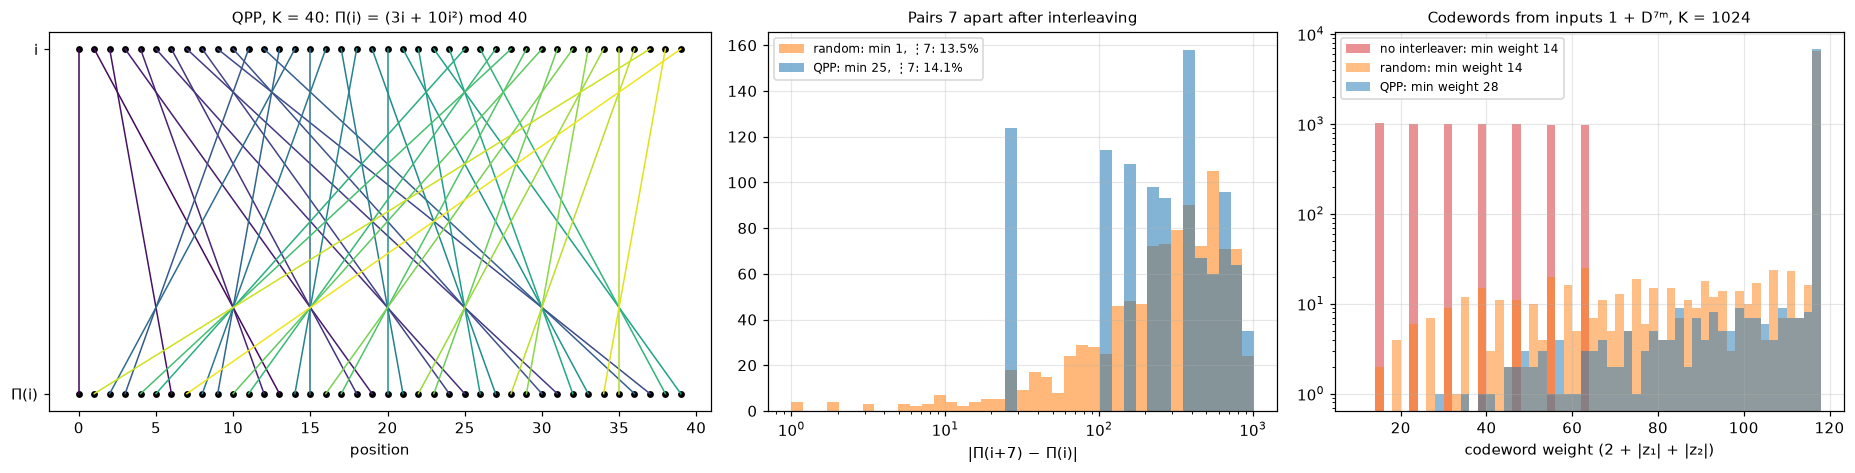

no interleaver : minimum weight  14, codewords of weight < 30:  2027 of 6972
random         : minimum weight  14, codewords of weight < 30:    19 of 6972
QPP            : minimum weight  28, codewords of weight < 30:     1 of 6972

K = 40: ones at 5 and 12 (1 + D⁷) → Π moves them to [25 36] (distance 11); weight of z₁ = 6, z₂ = 14
codeword length: 3·1024 + 12 = 3084, R = 0.3320


In [5]:
K3 = K_TURBO
pis = {"no interleaver": np.arange(K3), "random": np.random.default_rng(0).permutation(K3), "QPP": qpp(K3)}
pairs = np.array([(i, i + d) for d in range(7, 50, 7) for i in range(K3 - d)])
U2 = np.zeros((len(pairs), K3), np.int8); U2[np.arange(len(pairs)), pairs[:, 0]] = 1; U2[np.arange(len(pairs)), pairs[:, 1]] = 1
wts = {name: turbo_encode(U2, p).sum(1) for name, p in pis.items()}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1.3, 1, 1]})
p40 = qpp(40)
for i in range(40):
    ax[0].plot([i, p40[i]], [1, 0], color=plt.cm.viridis(i / 40), lw=1)
ax[0].scatter(range(40), np.ones(40), s=12, c="k"); ax[0].scatter(range(40), np.zeros(40), s=12, c="k")
ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["Π(i)", "i"]); ax[0].set_xlabel("position"); ax[0].grid(False)
ax[0].set_title(f"QPP, K = 40: Π(i) = ({QPP[40][0]}i + {QPP[40][1]}i²) mod 40", fontsize=10)
i7 = np.arange(K3 - 7)
for name, col in [("random", "C1"), ("QPP", "C0")]:
    p = pis[name]; sep = np.abs(p[i7 + 7] - p[i7])
    ax[1].hist(sep, np.logspace(0, np.log10(K3), 40), alpha=0.55, color=col,
               label=f"{name}: min {sep.min()}, ⋮7: {np.mean(sep % 7 == 0):.1%}")
ax[1].set_xscale("log"); ax[1].set_xlabel("|Π(i+7) − Π(i)|"); ax[1].legend(fontsize=8); ax[1].set_title("Pairs 7 apart after interleaving", fontsize=10)
bins = np.arange(10, 120, 2)
for (name, w), col in zip(wts.items(), ["C3", "C1", "C0"]):
    ax[2].hist(np.minimum(w, 118), bins, alpha=0.5, color=col, label=f"{name}: min weight {w.min()}")
ax[2].set_yscale("log"); ax[2].set_xlabel("codeword weight (2 + |z₁| + |z₂|)"); ax[2].legend(fontsize=8)
ax[2].set_title(f"Codewords from inputs 1 + D⁷ᵐ, K = {K3}", fontsize=10)
plt.tight_layout(); plt.show()

for name, w in wts.items():
    print(f"{name:15s}: minimum weight {w.min():3d}, codewords of weight < 30: {np.sum(w < 30):5d} of {len(w)}")
u_t = np.zeros((1, 40), int); u_t[0, [5, 12]] = 1
c_t = turbo_encode(u_t)
print(f"\nK = 40: ones at 5 and 12 (1 + D⁷) → Π moves them to {p40[[5, 12]]} (distance {abs(p40[12] - p40[5])}); "
      f"weight of z₁ = {c_t[0, 1:120:3].sum()}, z₂ = {c_t[0, 2:120:3].sum()}")
print(f"codeword length: 3·{K_TURBO} + 12 = {3 * K_TURBO + 12}, R = {R3:.4f}")

## 4. BCJR: the optimal decoder for one convolutional code
For every bit we need $P(u_t\,|\,\mathbf y)$, the sum of the probabilities of all trellis paths with that value of $u_t$. There are $2^K$ paths, but because the encoder is Markov the probability factorizes. The probability of edge $s\to s'$ at step $t$ is
$$P(s_t=s,\,s_{t+1}=s',\,\mathbf y)=\underbrace{\alpha_t(s)}_{\text{past}}\ \underbrace{\gamma_t(s,s')}_{\text{this step}}\ \underbrace{\beta_{t+1}(s')}_{\text{future}},$$
$$\alpha_{t+1}(s')=\sum_s\alpha_t(s)\gamma_t(s,s'),\qquad \beta_t(s)=\sum_{s'}\gamma_t(s,s')\beta_{t+1}(s'),\qquad \alpha_0=\beta_T=\delta_{s,0}.$$
Two recursions (forward and backward) over $8\times2$ edges per step: complexity $O(K)$ instead of $O(2^K)$.

**In logarithms.** $\bar\gamma_t(s,u)=\tfrac12x_u\,(L_s+L_a)+\tfrac12z_{s,u}L_p$, where $x_u,z_{s,u}\in\{\pm1\}$ are the edge's systematic and parity symbols (constant factors cancel in the ratio). A sum of exponentials becomes $\max^*$:
$$\bar\alpha_{t+1}(s')=\max\nolimits^*_{s\to s'}\big(\bar\alpha_t(s)+\bar\gamma_t(s,u)\big),\qquad L_\text{post}(u_t)=\max\nolimits^*_{u=0}\big(\bar\alpha+\bar\gamma+\bar\beta\big)-\max\nolimits^*_{u=1}\big(\bar\alpha+\bar\gamma+\bar\beta\big).$$
After every step $\bar\alpha$ is normalized (its maximum is subtracted), since only differences matter.

**Splitting the output.** The systematic term $\tfrac12x_u(L_s+L_a)$ is the same on every edge with a given $u$, so it factors out:
$$L_\text{post}=L_s+L_a+L_e,$$
and $L_e$ depends only on the parity bits and on **other** bits. This is the new knowledge the decoder extracted from its code.

Below: an 8-bit RSC plus tail through the channel. BCJR is compared with **brute force** over all $2^8=256$ codewords.

 bit  u   L_s     BCJR   brute  | max-log  brute max   |  L_e = L_post − L_s
  0   1   -2.86  -11.07  -11.07  | -11.77   -11.77     |   -8.21
  1   1   -1.14   -4.96   -4.96  |  -5.95    -5.95     |   -3.82
  2   1   +0.66   -4.92   -4.92  |  -5.95    -5.95     |   -5.59
  3   0   +3.64   +8.16   +8.16  |  +8.76    +8.76     |   +4.52
  4   0   +0.48   +4.42   +4.42  |  +5.44    +5.44     |   +3.94
  5   0   -0.59   +4.60   +4.60  |  +5.44    +5.44     |   +5.19
  6   0   +0.64   +4.50   +4.50  |  +5.44    +5.44     |   +3.86
  7   0   +1.91   +4.97   +4.97  |  +5.95    +5.95     |   +3.06
channel errors in the systematic bits: [2 5]; BCJR fixed them from the parity and the tail
max |BCJR − brute force| = 5.3e-15, max-log: 3.6e-15  (max-log = best path = Viterbi)

Step 0 unrolled: two edges leave state 0, L_s = -2.86, L_p = -6.28
  u=0 → s'=0, z=0: γ̄ = ½·(+1)·L_s + ½·(+1)·L_p = -4.568
  u=1 → s'=4, z=1: γ̄ = ½·(-1)·L_s + ½·(-1)·L_p = +4.568
  ᾱ₁ after normalization: [-9.137   -inf   -

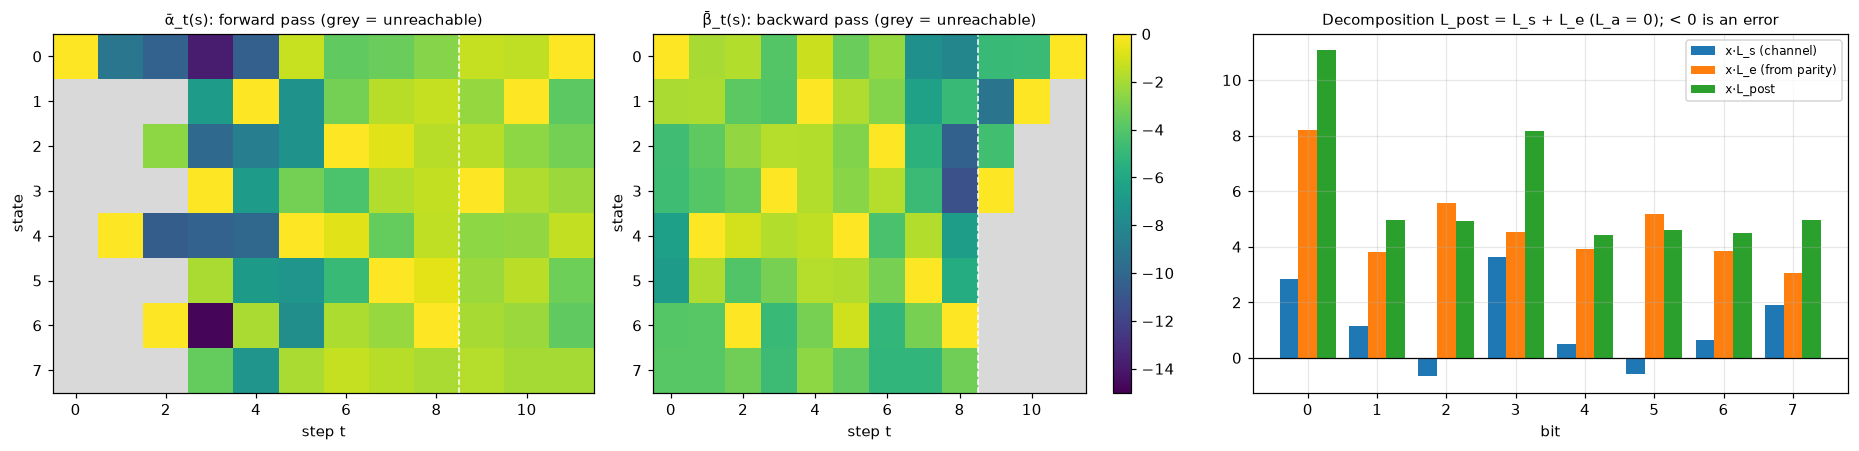

In [6]:
from scipy.special import logsumexp
K8 = 8
R8 = K8 / (2 * K8 + 6)
La8 = np.zeros(K8)
for seed8 in range(500):                          # look for noise: a systematic error that BCJR fixes
    r8 = np.random.default_rng(seed8)
    u8 = r8.integers(0, 2, (1, K8)); z8, xt8, zt8 = rsc_encode(u8)
    Lc8 = channel(np.concatenate([u8, z8, xt8, zt8], 1), 1.0, R8, r8)[0]
    Ls8, Lp8, Lst8, Lpt8 = Lc8[:K8], Lc8[K8:2 * K8], Lc8[2 * K8:2 * K8 + 3], Lc8[2 * K8 + 3:]
    tr = {}
    Lpost8 = bcjr(Ls8[None], Lp8[None], La8[None], Lst8[None], Lpt8[None], True, trace=tr)[0]
    if ((Ls8 < 0) != u8[0]).any() and ((Lpost8 < 0) == u8[0]).all(): break
Lml8 = bcjr(Ls8[None], Lp8[None], La8[None], Lst8[None], Lpt8[None], False)[0]

allu = np.array([[(w >> i) & 1 for i in range(K8)] for w in range(2 ** K8)])
za, xta, zta = rsc_encode(allu)
met = 0.5 * ((1 - 2 * allu) @ (Ls8 + La8) + (1 - 2 * za) @ Lp8 + (1 - 2 * xta) @ Lst8 + (1 - 2 * zta) @ Lpt8)   # ln P(y|codeword) + const
bf = np.array([logsumexp(met[allu[:, k] == 0]) - logsumexp(met[allu[:, k] == 1]) for k in range(K8)])
bfm = np.array([met[allu[:, k] == 0].max() - met[allu[:, k] == 1].max() for k in range(K8)])
x8 = 1 - 2 * u8[0]
print(" bit  u   L_s     BCJR   brute  | max-log  brute max   |  L_e = L_post − L_s")
for k in range(K8):
    print(f"  {k}   {u8[0, k]}  {Ls8[k]:+6.2f}  {Lpost8[k]:+6.2f}  {bf[k]:+6.2f}  | {Lml8[k]:+6.2f}   {bfm[k]:+6.2f}     |  {Lpost8[k] - Ls8[k]:+6.2f}")
print(f"channel errors in the systematic bits: {np.nonzero((Ls8 < 0) != u8[0])[0]}; BCJR fixed them from the parity and the tail")
print(f"max |BCJR − brute force| = {np.abs(Lpost8 - bf).max():.1e}, max-log: {np.abs(Lml8 - bfm).max():.1e}  (max-log = best path = Viterbi)")

g0 = tr["g"][0, 0]
print(f"\nStep 0 unrolled: two edges leave state 0, L_s = {Ls8[0]:+.2f}, L_p = {Lp8[0]:+.2f}")
for b in (0, 1):
    print(f"  u={b} → s'={NXT[0, b]}, z={PAR[0, b]}: γ̄ = ½·({1 - 2 * b:+d})·L_s + ½·({1 - 2 * PAR[0, b]:+d})·L_p = {g0[0, b]:+.3f}")
print(f"  ᾱ₁ after normalization: {np.round(np.where(tr['al'][1, 0] < -1e8, -np.inf, tr['al'][1, 0]), 3)}  (other states unreachable)")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for a, M, t in [(ax[0], tr["al"][:, 0].T, "ᾱ_t(s): forward pass"), (ax[1], tr["be"][:, 0].T, "β̄_t(s): backward pass")]:
    Mm = np.ma.masked_less(M, -1e8)
    im = a.imshow(np.maximum(Mm, -15), cmap="viridis", aspect="auto", vmin=-15, vmax=0); a.grid(False)
    a.set_facecolor("0.85"); a.set_xlabel("step t"); a.set_ylabel("state"); a.set_title(t + " (grey = unreachable)", fontsize=10)
    a.axvline(K8 + 0.5, color="w", ls="--", lw=1)
plt.colorbar(im, ax=ax[1])
kk = np.arange(K8)
ax[2].bar(kk - 0.27, x8 * Ls8, 0.27, label="x·L_s (channel)")
ax[2].bar(kk, x8 * (Lpost8 - Ls8), 0.27, label="x·L_e (from parity)")
ax[2].bar(kk + 0.27, x8 * Lpost8, 0.27, label="x·L_post")
ax[2].axhline(0, color="k", lw=0.8); ax[2].set_xlabel("bit"); ax[2].legend(fontsize=8)
ax[2].set_title("Decomposition L_post = L_s + L_e (L_a = 0); < 0 is an error", fontsize=10)
plt.tight_layout(); plt.show()

## 5. $\max^*$ and max-log-MAP
$$\max\nolimits^*(a,b)=\ln(e^a+e^b)=\max(a,b)+\ln\big(1+e^{-|a-b|}\big).$$
The correction is at most $\ln2\approx0.69$ and fades quickly with $|a-b|$. **max-log-MAP** drops it: only additions and comparisons remain (as in the Viterbi algorithm), and $\sigma^2$ need not be known, because the LLR scale does not affect the decisions. The price is that extrinsic information is **overestimated** in magnitude: max-log only counts the best path, not the "crowd" of competitors. So in a turbo decoder the max-log extrinsic LLRs are multiplied by $\approx0.7$ (`SCALE_ML`), like $\alpha$ in min-sum for LDPC.

Right: that factor estimated from data, log-MAP vs. max-log extrinsic LLRs of one BCJR on a $K$ = `K_TURBO` block at `EBN0_DB`.

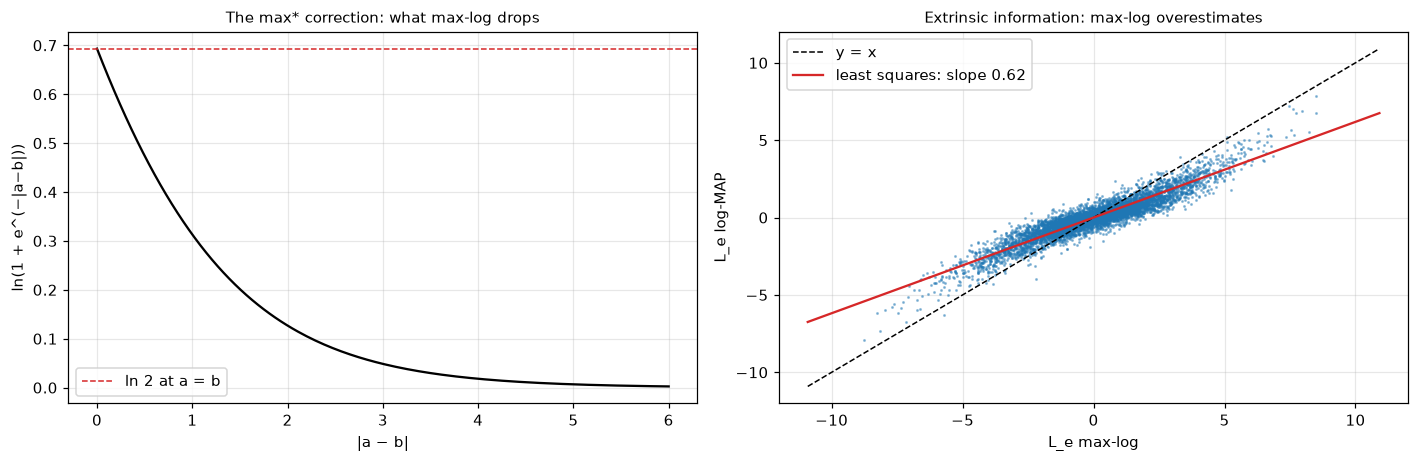

Sign agreement of L_e: 87.63%; slope 0.62, hence SCALE_ML ≈ 0.7


In [7]:
dd = np.linspace(0, 6, 200)
r5 = np.random.default_rng(6)
u5 = r5.integers(0, 2, (20, K_TURBO)); c5 = turbo_encode(u5)
L5 = channel(c5, EBN0_DB, R3, r5); m5 = L5[:, :3 * K_TURBO].reshape(20, K_TURBO, 3)
args = (m5[..., 0], m5[..., 1], np.zeros((20, K_TURBO)), L5[:, 3 * K_TURBO:3 * K_TURBO + 3], L5[:, 3 * K_TURBO + 3:3 * K_TURBO + 6])
Le_ex = bcjr(*args, True) - m5[..., 0]; Le_ml = bcjr(*args, False) - m5[..., 0]
k_fit = np.sum(Le_ex * Le_ml) / np.sum(Le_ml ** 2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].plot(dd, np.log1p(np.exp(-dd)), "k"); ax[0].axhline(np.log(2), color="C3", ls="--", lw=1, label="ln 2 at a = b")
ax[0].set_xlabel("|a − b|"); ax[0].set_ylabel("ln(1 + e^(−|a−b|))"); ax[0].legend(); ax[0].set_title("The max* correction: what max-log drops", fontsize=10)
sel = r5.choice(Le_ex.size, 6000, replace=False)
ax[1].plot(Le_ml.ravel()[sel], Le_ex.ravel()[sel], ".", ms=2, alpha=0.4)
lim = np.abs(Le_ml).max(); ll = np.array([-lim, lim])
ax[1].plot(ll, ll, "k--", lw=1, label="y = x"); ax[1].plot(ll, k_fit * ll, "C3", label=f"least squares: slope {k_fit:.2f}")
ax[1].set_xlabel("L_e max-log"); ax[1].set_ylabel("L_e log-MAP"); ax[1].legend(); ax[1].set_title("Extrinsic information: max-log overestimates", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Sign agreement of L_e: {np.mean(np.sign(Le_ex) == np.sign(Le_ml)):.2%}; slope {k_fit:.2f}, hence SCALE_ML ≈ 0.7")

## 6. Extrinsic information and the "echo"
Decoder 1 got a priori information $L_a$ from decoder 2 and produced $L_\text{post}=L_s+L_a+L_{e1}$. If the whole $L_\text{post}$ were passed to the neighbour:
- $L_a$ is the neighbour's own earlier opinion: it would get it back and take it as **confirmation**;
- the neighbour already knows $L_s$ from the channel, so it would be counted twice.

That is positive feedback: confidence grows while errors freeze in place. So only $L_{e1}=L_\text{post}-L_s-L_a$ is passed on: what the decoder learned **from its own parity bits** and the neighbour doesn't have. Links between bits inside one convolutional code are short, so one iteration achieves little. The interleaver makes sure that decoder 1's extrinsic information reaches decoder 2 from bits that are far apart in decoder 2's trellis, i.e. almost independently.

Experiment: $K$ = `K_TURBO`, `EBN0_DB`, no early stopping; the "echo" decoder passes $L_\text{post}-L_s$ (only the channel is subtracted).

extrinsic (correct)               : BER = 2.79e-03, FER = 0.03


echo: neighbour gets L_post − L_s : BER = 7.43e-02, FER = 0.95


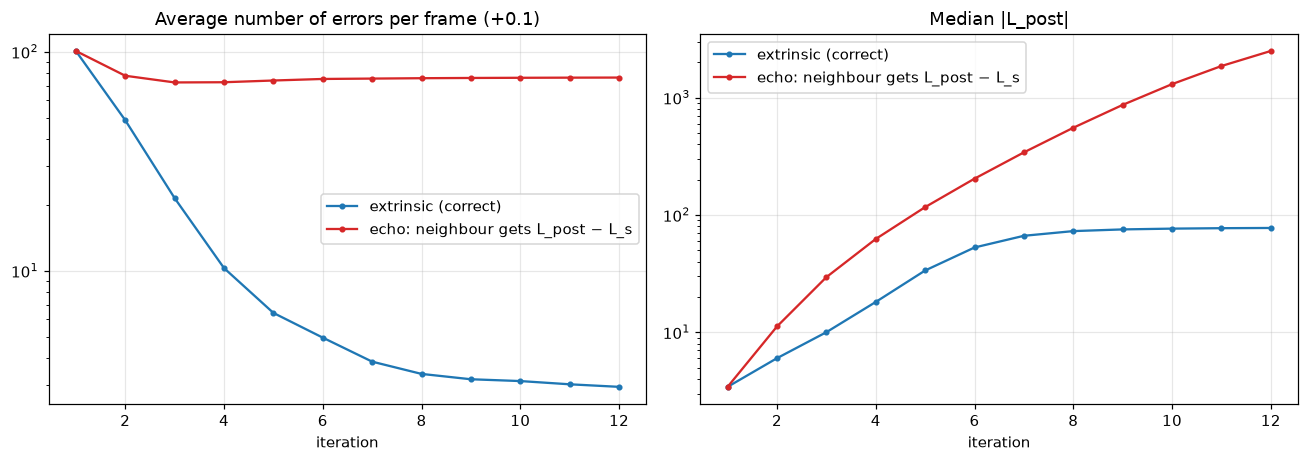

In [8]:
F6 = 200
u6 = rng.integers(0, 2, (F6, K_TURBO)); x6 = 1 - 2.0 * u6
L6 = channel(turbo_encode(u6), EBN0_DB, R3, rng)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for ext, col, name in [(True, "C0", "extrinsic (correct)"), (False, "C3", "echo: neighbour gets L_post − L_s")]:
    tr6 = []
    uh, _ = turbo_decode(L6, K_TURBO, 12, extrinsic=ext, early=False,
                         cb=lambda it, d: tr6.append(((d["L2"] * x6 < 0).sum(1).mean(), np.median(np.abs(d["L2"])))))
    tr6 = np.array(tr6); its = np.arange(1, len(tr6) + 1)
    ax[0].semilogy(its, tr6[:, 0] + 0.1, "o-", ms=3, color=col, label=name); ax[1].semilogy(its, tr6[:, 1], "o-", ms=3, color=col, label=name)
    print(f"{name:34s}: BER = {np.mean(uh != u6):.2e}, FER = {np.mean((uh != u6).any(1)):.2f}")
ax[0].set_title("Average number of errors per frame (+0.1)"); ax[1].set_title("Median |L_post|")
for a in ax: a.set_xlabel("iteration"); a.legend()
plt.tight_layout(); plt.show()

## 7. Turbo iterations by hand: $K=40$
This is the shortest LTE block. We pick a noise realization at $E_b/N_0=0$ dB where the systematic bits contain many errors, decoder 1 alone can't fix them, but the exchange can. For every iteration we see:
- how many errors remain after decoder 1 (convolutional code + a priori) and after decoder 2;
- how $L_\text{post}=L_s+L_a+L_e$ builds up for the erroneous bits: the channel says the wrong thing, but the extrinsic information from both decoders gradually outweighs it.

The colour is the LLR multiplied by the transmitted sign $x$ (blue is right, red is an error).

After convergence the LLRs **stop growing**. A competing trellis path that differs at bit $t$ can "close" through the tail, so that it differs only in symbols with channel-only information (the tail and parity bits), which a priori information does not strengthen. The extrinsic information is bounded, and further iterations change nothing; this is also why early stopping works.

seed = 19: 8 channel errors in the systematic bits (bits [ 1  2 12 30 31 33 36 38])
  iteration 1: after decoder 1,  7 errors; after decoder 2,  7
  iteration 2: after decoder 1,  3 errors; after decoder 2,  2
  iteration 3: after decoder 1,  0 errors; after decoder 2,  0
  iteration 4: after decoder 1,  0 errors; after decoder 2,  0

Bit 1 (sent x = +1), everything multiplied by x:
 iter |  L_s    L_a1    L_e1   L_post1 |  L_a2=L_e1  L_e2   L_post2
  1   |  -0.13   +0.00   +3.54    +3.41 |     +3.54    +0.60    +4.01
  2   |  -0.13   +0.60   +7.50    +7.97 |     +7.50    -0.39    +6.98
  3   |  -0.13   -0.39  +13.10   +12.58 |    +13.10    +7.30   +20.27
  4   |  -0.13   +7.30  +24.40   +31.56 |    +24.40    +7.95   +32.22
  check: L_post1 = L_s + L_a1 + L_e1 → True ; L_post2 = L_s + L_e1 + L_e2 → True


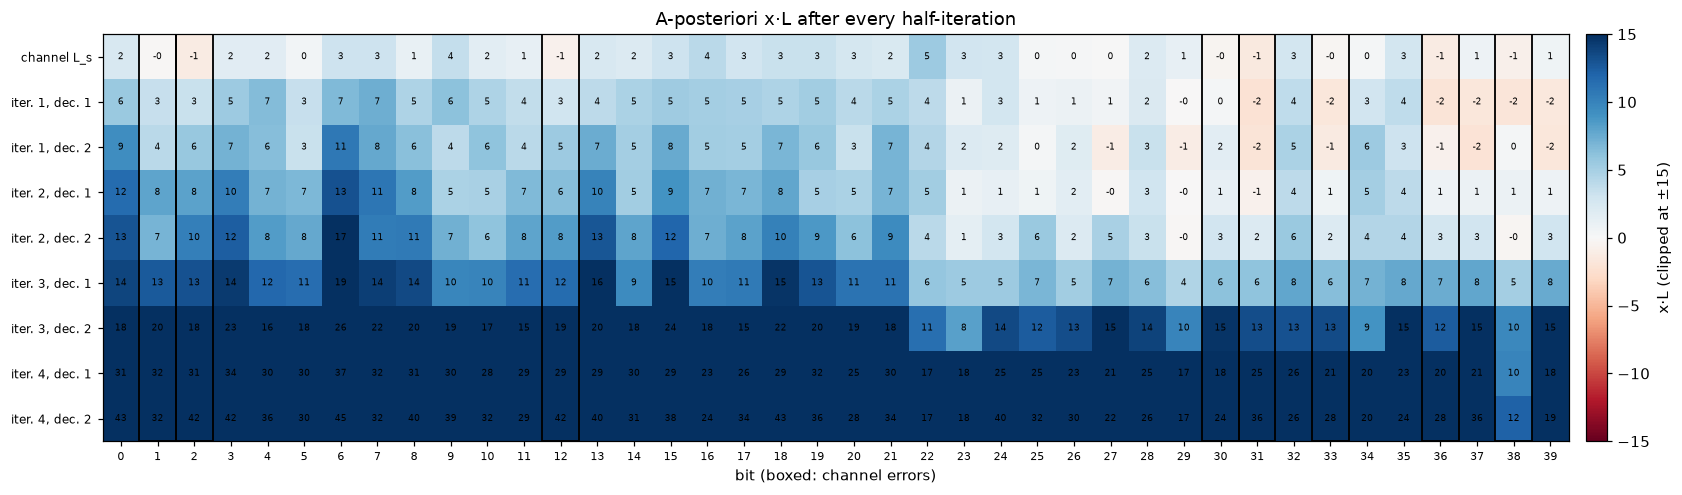

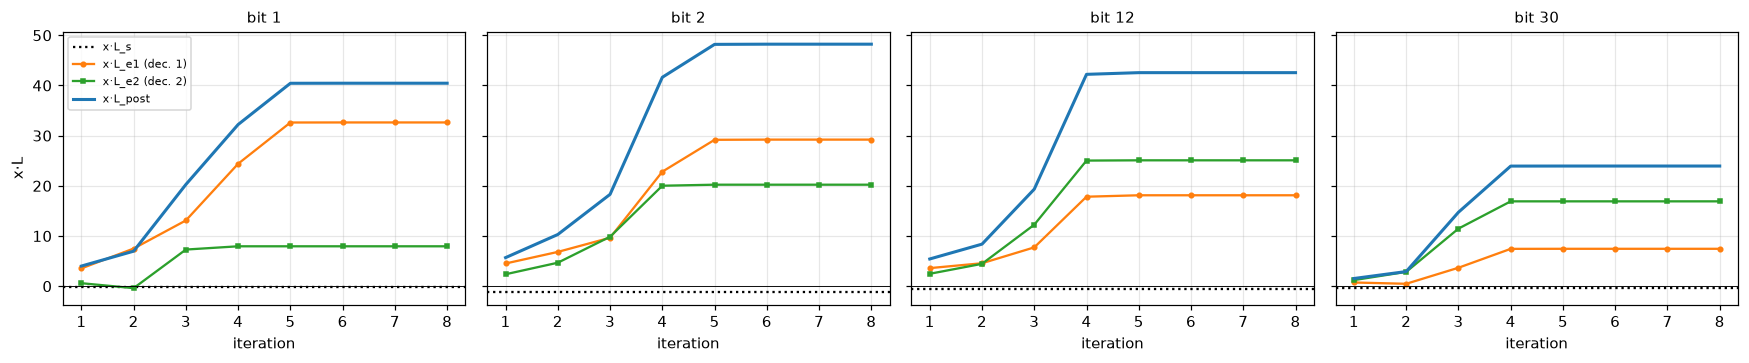

In [9]:
K7 = 40; R7 = K7 / (3 * K7 + 12)
for seed in range(3000):                          # channel: ≥4 systematic errors; the decoder needs ≥3 iterations
    rs = np.random.default_rng(seed)
    u7 = rs.integers(0, 2, (1, K7)); L7 = channel(turbo_encode(u7), 0.0, R7, rs)
    rec = []
    uh7, _ = turbo_decode(L7, K7, ITERS, early=False, cb=lambda it, d: rec.append({k: v[0].copy() for k, v in d.items()}))
    e1 = [((r["L1"] < 0) != u7[0]).sum() for r in rec]; e2 = [((r["L2"] < 0) != u7[0]).sum() for r in rec]
    if (uh7 == u7).all() and ((L7[0, 0:3 * K7:3] < 0) != u7[0]).sum() >= 4 and e2[0] > 0 and e2[1] > 0 and e2[2] == 0:
        break
x7 = 1 - 2.0 * u7[0]; Ls7 = L7[0, 0:3 * K7:3]
err7 = np.nonzero((Ls7 < 0) != u7[0])[0]
print(f"seed = {seed}: {len(err7)} channel errors in the systematic bits (bits {err7})")
for it in range(4):
    print(f"  iteration {it + 1}: after decoder 1, {e1[it]:2d} errors; after decoder 2, {e2[it]:2d}")
b = err7[0]
print(f"\nBit {b} (sent x = {x7[b]:+.0f}), everything multiplied by x:")
print(" iter |  L_s    L_a1    L_e1   L_post1 |  L_a2=L_e1  L_e2   L_post2")
for it in range(4):
    r = rec[it]
    print(f"  {it + 1}   | {x7[b] * Ls7[b]:+6.2f} {x7[b] * r['La1'][b]:+7.2f} {x7[b] * r['Le1'][b]:+7.2f} {x7[b] * r['L1'][b]:+8.2f} |"
          f"   {x7[b] * r['Le1'][b]:+7.2f}  {x7[b] * r['Le2'][b]:+7.2f} {x7[b] * r['L2'][b]:+8.2f}")
print("  check: L_post1 = L_s + L_a1 + L_e1 →", np.allclose(rec[0]["L1"], Ls7 + rec[0]["La1"] + rec[0]["Le1"]),
      "; L_post2 = L_s + L_e1 + L_e2 →", np.allclose(rec[0]["L2"], Ls7 + rec[0]["Le1"] + rec[0]["Le2"]))

rows = [x7 * Ls7] + sum([[x7 * rec[it]["L1"], x7 * rec[it]["L2"]] for it in range(4)], [])
labels = ["channel L_s"] + sum([[f"iter. {it + 1}, dec. 1", f"iter. {it + 1}, dec. 2"] for it in range(4)], [])
M7 = np.array(rows)
fig, a = plt.subplots(figsize=(17, 4.6))
im = a.imshow(np.clip(M7, -15, 15), cmap="RdBu", vmin=-15, vmax=15, aspect="auto"); a.grid(False)
for (i, j), v in np.ndenumerate(M7): a.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6)
a.set_yticks(range(len(labels))); a.set_yticklabels(labels, fontsize=8); a.set_xticks(range(K7)); a.set_xticklabels(range(K7), fontsize=7)
for j in err7: a.add_patch(plt.Rectangle((j - 0.5, -0.5), 1, len(labels), fill=False, ec="k", lw=1.2))
a.set_xlabel("bit (boxed: channel errors)"); plt.colorbar(im, ax=a, label="x·L (clipped at ±15)", pad=0.01)
a.set_title("A-posteriori x·L after every half-iteration")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, min(4, len(err7)), figsize=(16, 3.4), sharey=True)
hs = np.arange(1, ITERS + 1)
for a, b in zip(np.atleast_1d(ax), err7[:4]):
    a.axhline(x7[b] * Ls7[b], color="k", ls=":", label="x·L_s")
    a.plot(hs, [x7[b] * r["Le1"][b] for r in rec], "C1o-", ms=3, label="x·L_e1 (dec. 1)")
    a.plot(hs, [x7[b] * r["Le2"][b] for r in rec], "C2s-", ms=3, label="x·L_e2 (dec. 2)")
    a.plot(hs, [x7[b] * r["L2"][b] for r in rec], "C0-", lw=2, label="x·L_post")
    a.axhline(0, color="k", lw=0.6); a.set_title(f"bit {b}", fontsize=10); a.set_xlabel("iteration")
np.atleast_1d(ax)[0].legend(fontsize=7); np.atleast_1d(ax)[0].set_ylabel("x·L")
plt.tight_layout(); plt.show()

# Part II. $K = 1024$ at work

## 8. Iterations from the inside
100 frames at `EBN0_DB`, all `ITERS` iterations, no early stopping. Left: the errors in each frame after every half-iteration (decoder 1, decoder 2, …). As with LDPC, convergence is an avalanche: while the extrinsic information is weak the half-iterations achieve little, then the errors vanish within 1–2 iterations. Red frames did not converge. Right: the distribution of the a-posteriori $x\cdot L$. The mass moves right, and confidence grows by orders of magnitude.

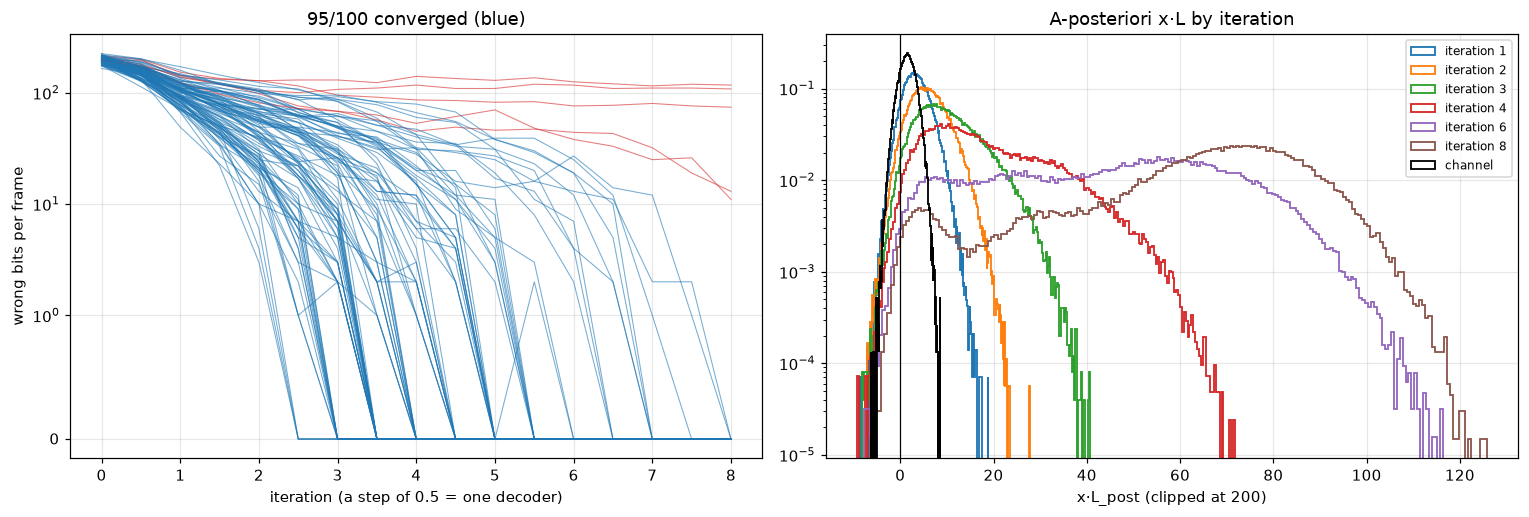

Channel errors in the systematic bits: 197 of 1024 (19.3%); after decoding: BER = 3.2e-03, FER = 0.05


In [10]:
F8 = 100
u8b = rng.integers(0, 2, (F8, K_TURBO)); x8b = 1 - 2.0 * u8b
L8b = channel(turbo_encode(u8b), EBN0_DB, R3, rng)
hist8 = []
def rec8(it, d):
    hist8.append(dict(e1=(d["L1"] * x8b < 0).sum(1), e2=(d["L2"] * x8b < 0).sum(1), xL=(d["L2"] * x8b).astype(np.float32),
                      IA=mi(d["La1"], x8b), IE1=mi(d["Le1"], x8b), IE2=mi(d["Le2"], x8b)))
uh8, _ = turbo_decode(L8b, K_TURBO, ITERS, early=False, cb=rec8)
E8 = np.array([(L8b[:, 0:3 * K_TURBO:3] * x8b < 0).sum(1)] + sum([[h["e1"], h["e2"]] for h in hist8], []))
conv8 = (uh8 == u8b).all(1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
hx = np.arange(E8.shape[0]) / 2
for f in range(F8):
    ax[0].plot(hx, E8[:, f], color="C0" if conv8[f] else "C3", lw=0.7, alpha=0.6)
ax[0].set_yscale("symlog", linthresh=1); ax[0].set_xlabel("iteration (a step of 0.5 = one decoder)"); ax[0].set_ylabel("wrong bits per frame")
ax[0].set_title(f"{conv8.sum()}/{F8} converged (blue)")
for it in [0, 1, 2, 3, 5, ITERS - 1]:
    if it < len(hist8):
        ax[1].hist(np.clip(hist8[it]["xL"].ravel(), -30, 200), 200, density=True, histtype="step", lw=1.2, label=f"iteration {it + 1}")
ax[1].hist(np.clip((L8b[:, 0:3 * K_TURBO:3] * x8b).ravel(), -30, 200), 200, density=True, histtype="step", lw=1.2, color="k", label="channel")
ax[1].set_yscale("log"); ax[1].axvline(0, color="k", lw=0.8); ax[1].legend(fontsize=8); ax[1].set_xlabel("x·L_post (clipped at 200)")
ax[1].set_title("A-posteriori x·L by iteration")
plt.tight_layout(); plt.show()
print(f"Channel errors in the systematic bits: {E8[0].mean():.0f} of {K_TURBO} ({E8[0].mean() / K_TURBO:.1%}); after decoding: BER = {np.mean(uh8 != u8b):.1e}, FER = {1 - conv8.mean():.2f}")

## 9. The EXIT chart and the threshold
Describe the decoder's a priori input with a single number, its mutual information $I_A$ with the bit, treating it as a Gaussian LLR $\mathcal N(x\sigma_A^2/2,\sigma_A^2)$ with $I_A=J(\sigma_A)$ (as in the LDPC EXIT chart). Feed such an $L_a$ into one BCJR together with the channel and measure the information of the extrinsic output, $I_E=I(L_e;x)$. The result is a **transfer characteristic** $I_E=T(I_A)$. It is measured by Monte Carlo; there is no formula, because a convolutional code is too complex.

Both encoders are identical, so the second curve is the same $T$ mirrored about the diagonal. The decoder walks a "staircase": $I_{A1}\to I_{E1}=I_{A2}\to I_{E2}=I_{A1}\to\dots$ As long as there is a **tunnel** between the curves ($T(I)>I$ for all $I<1$), the staircase reaches $I=1$. The **threshold** is the $E_b/N_0$ at which the tunnel opens. Unlike LDPC, $T(0)>0$: even without a priori information the convolutional code extracts something from its own parity.

Left: below the threshold. Right: `EBN0_DB` and the **measured** trajectory from section 8.

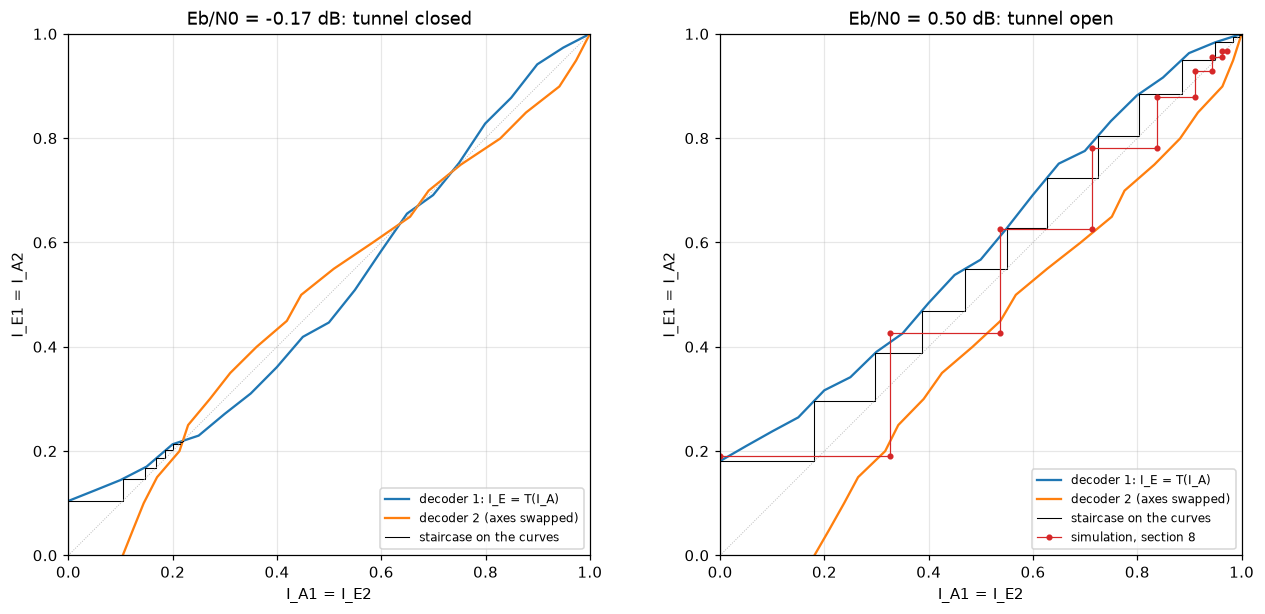

EXIT threshold: 0.13 dB; Shannon for BPSK at R = 1/3: -0.50 dB → gap 0.6 dB
Minimum gap T(I) − I by Eb/N0: -0.4: -0.092  -0.3: -0.075  -0.2: -0.058  -0.1: -0.040  -0.0: -0.023  +0.1: -0.005  +0.2: +0.013  +0.3: +0.031  +0.4: +0.033  +0.5: +0.035  +0.6: +0.036


In [11]:
def exit_curve(e, IA, K=K_TURBO, B=20, seed=0):
    r_ = np.random.default_rng(seed)
    u_ = r_.integers(0, 2, (B, K)); L_ = channel(turbo_encode(u_), e, R3, r_)
    m_ = L_[:, :3 * K].reshape(B, K, 3); x_ = 1 - 2.0 * u_
    out = []
    for I in IA:
        sA = Jinv(I); La_ = sA ** 2 / 2 * x_ + sA * r_.standard_normal(x_.shape)     # Gaussian a priori carrying information I
        L1_ = bcjr(m_[..., 0], m_[..., 1], La_, L_[:, 3 * K:3 * K + 3], L_[:, 3 * K + 3:3 * K + 6])
        out.append(mi(L1_ - m_[..., 0] - La_, x_))
    return np.array(out)

IA = np.linspace(0, 0.999, 21)
eg = np.arange(-0.4, 0.61, 0.1)
gaps = np.array([(exit_curve(e, IA) - IA)[:-1].min() for e in eg])
TH_T = float(np.interp(0, gaps, eg))

def stairs(T_, start=0.0, n=60):
    xs, ys, I = [start], [0.0], start
    for _ in range(n):
        Ie = float(np.interp(I, IA, T_)); xs += [I, Ie]; ys += [Ie, Ie]; I = Ie
        if I > 0.999: break
    return xs, ys

fig, ax = plt.subplots(1, 2, figsize=(12, 5.6))
for a, e in zip(ax, [TH_T - 0.3, EBN0_DB]):
    T_ = exit_curve(e, IA)
    a.plot(IA, T_, "C0", lw=1.5, label="decoder 1: I_E = T(I_A)")
    a.plot(T_, IA, "C1", lw=1.5, label="decoder 2 (axes swapped)")
    a.plot(*stairs(T_), "k", lw=0.7, label="staircase on the curves")
    a.plot([0, 1], [0, 1], color="0.7", lw=0.6, ls=":")
    a.set_title(f"Eb/N0 = {e:.2f} dB: tunnel {'open' if (T_ - IA)[:-1].min() > 0 else 'closed'}")
    a.set_xlabel("I_A1 = I_E2"); a.set_ylabel("I_E1 = I_A2"); a.set_xlim(0, 1); a.set_ylim(0, 1); a.set_aspect("equal")
xs, ys = [], []
for h in hist8:
    xs += [h["IA"], h["IE2"]]; ys += [h["IE1"], h["IE1"]]
ax[1].plot(xs, ys, "C3o-", ms=3, lw=0.8, label=f"simulation, section 8")
for a in ax: a.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()
print(f"EXIT threshold: {TH_T:.2f} dB; Shannon for BPSK at R = 1/3: {biawgn_limit(1 / 3):.2f} dB → gap {TH_T - biawgn_limit(1 / 3):.1f} dB")
print("Minimum gap T(I) − I by Eb/N0:", "  ".join(f"{e:+.1f}: {g:+.3f}" for e, g in zip(eg, gaps)))

## 10. The waterfall: BER/FER vs. $E_b/N_0$
Three decoders: log-MAP (exact $\max^*$), max-log-MAP without scaling, and max-log-MAP scaled by `SCALE_ML`. For comparison, a **single** RSC (systematic + one parity sequence, $R\approx1/2$) decoded by one BCJR: "just a convolutional code" with the same trellis. The dashed lines are the Shannon limit at $R=1/3$ and the EXIT threshold; at finite length the waterfall sits to the right of the threshold.

Early stopping: a frame is frozen as soon as the hard decisions of both decoders agree (hardware usually checks the block CRC). Right: BER after each log-MAP iteration.

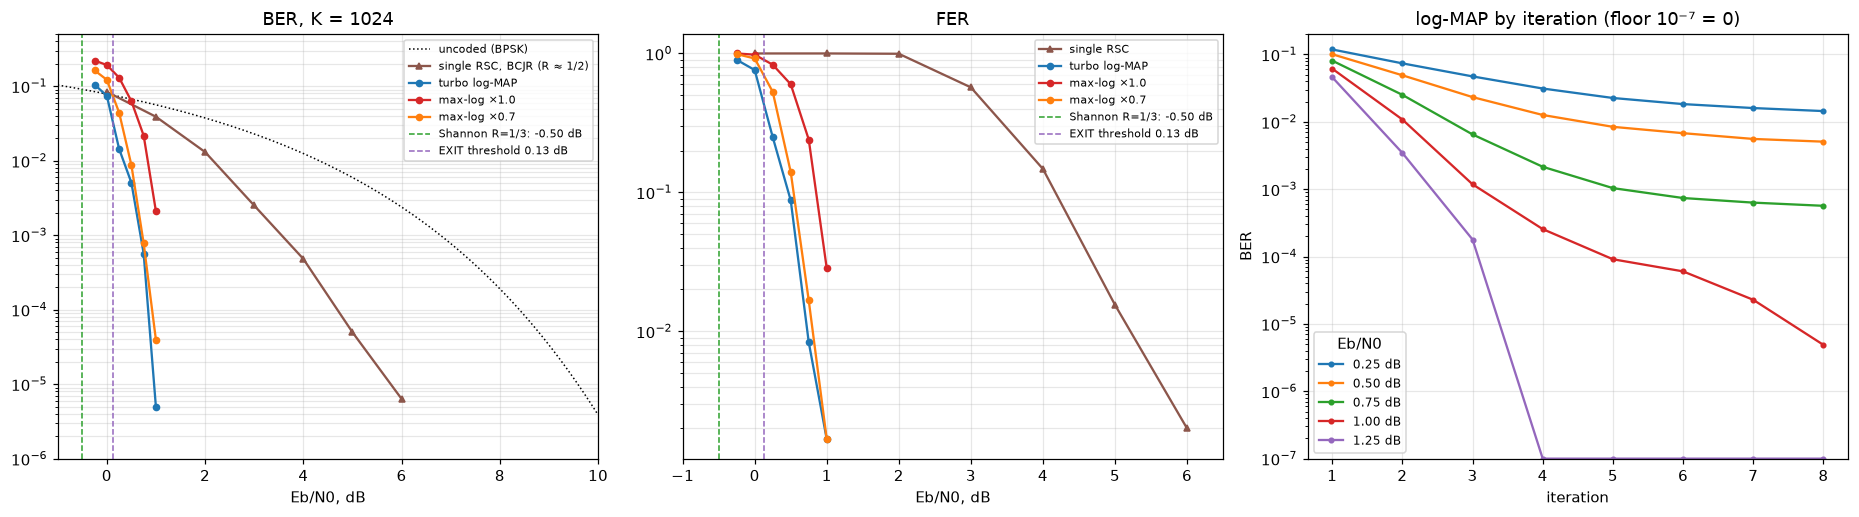

 Eb/N0 |  log-MAP: BER    FER | max-log×1: BER   FER | max-log×0.7: BER  FER  iter* | frames
 -0.25 |   1.1e-01  0.900 |   2.2e-01  1.000 |   1.6e-01  0.990   8.0 | 100
  0.00 |   7.5e-02  0.760 |   1.9e-01  0.980 |   1.2e-01  0.920   7.9 | 100
  0.25 |   1.4e-02  0.250 |   1.3e-01  0.830 |   4.4e-02  0.530   7.0 | 200
  0.50 |   5.1e-03  0.087 |   6.3e-02  0.600 |   8.8e-03  0.140   5.9 | 400
  0.75 |   5.7e-04  0.008 |   2.2e-02  0.240 |   7.8e-04  0.017   4.4 | 600
  1.00 |   4.9e-06  0.002 |   2.1e-03  0.028 |   3.9e-05  0.002   3.6 | 600
  1.25 |   0.0e+00  0.000 |   0.0e+00  0.000 |   0.0e+00  0.000   3.2 | 600
* average iterations with early stopping (log-MAP ran without it here, to record BER per iteration)
single RSC: 0 dB → BER 8.4e-02, 1 dB → BER 3.9e-02, 2 dB → BER 1.3e-02, 3 dB → BER 2.5e-03, 4 dB → BER 4.8e-04, 5 dB → BER 5.0e-05, 6 dB → BER 6.3e-06

BER = 1e-4: uncoded 8.4 dB, single RSC 4.7 dB, turbo 0.84 dB → gain 7.6 dB, of which 3.9 dB comes from the iterative exchan

In [12]:
def sim_turbo(ebn0_list, K=K_TURBO, exact=True, scale=SCALE_ML, pi=None, mask=None, min_fe=30, max_frames=600, batch=100, track=False):
    res, per_it = [], []
    for e in ebn0_list:
        be = fe = nf = its = 0; pit = np.zeros(ITERS)
        while fe < min_fe and nf < max_frames:
            u_ = rng.integers(0, 2, (batch, K)); c_ = turbo_encode(u_, pi)
            R_ = K / (c_.shape[1] if mask is None else mask.sum())
            L_ = channel(c_, e, R_, rng, mask)
            def cb(it, d): pit[it] += np.sum((d["L2"] < 0) != u_)
            uh, nit = turbo_decode(L_, K, ITERS, exact, scale, cb=cb if track else None, pi=pi, early=not track)   # no early stopping when tracking BER per iteration
            err = uh != u_; be += err.sum(); fe += err.any(1).sum(); nf += batch; its += nit.sum()
        res.append((be / (nf * K), fe / nf, its / nf, nf)); per_it.append(pit / (nf * K))
    return np.array(res), np.array(per_it)

def sim_rsc(ebn0_list, K=K_TURBO, min_fe=30, max_frames=2000, batch=200):
    res = []
    for e in ebn0_list:
        be = fe = nf = 0
        while fe < min_fe and nf < max_frames:
            u_ = rng.integers(0, 2, (batch, K)); z_, xt_, zt_ = rsc_encode(u_)
            c_ = np.concatenate([u_, z_, xt_, zt_], 1)
            L_ = channel(c_, e, K / c_.shape[1], rng)
            uh = (bcjr(L_[:, :K], L_[:, K:2 * K], np.zeros((batch, K)), L_[:, 2 * K:2 * K + 3], L_[:, 2 * K + 3:]) < 0)
            err = uh != u_; be += err.sum(); fe += err.any(1).sum(); nf += batch
        res.append((be / (nf * K), fe / nf, nf))
    return np.array(res)

eb10 = np.arange(-0.25, 1.26, 0.25)
r_log, it_log = sim_turbo(eb10, track=True)
r_ml1, _ = sim_turbo(eb10, exact=False, scale=1.0)
r_ml7, _ = sim_turbo(eb10, exact=False, scale=SCALE_ML)
eb_rsc = np.arange(0.0, 6.1, 1.0)
r_rsc = sim_rsc(eb_rsc)
SH3 = biawgn_limit(1 / 3)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
eg = np.linspace(-1, 10, 200)
ax[0].semilogy(eg, 0.5 * erfc(np.sqrt(10 ** (eg / 10))), "k:", lw=1, label="uncoded (BPSK)")
ok = r_rsc[:, 0] > 0
ax[0].semilogy(eb_rsc[ok], r_rsc[ok, 0], "^-", color="C5", ms=4, label="single RSC, BCJR (R ≈ 1/2)")
ax[1].semilogy(eb_rsc[r_rsc[:, 1] > 0], r_rsc[r_rsc[:, 1] > 0, 1], "^-", color="C5", ms=4, label="single RSC")
for r_, lab, c_ in [(r_log, "turbo log-MAP", "C0"), (r_ml1, "max-log ×1.0", "C3"), (r_ml7, f"max-log ×{SCALE_ML}", "C1")]:
    ok = r_[:, 0] > 0
    ax[0].semilogy(eb10[ok], r_[ok, 0], "o-", color=c_, ms=4, label=lab)
    ax[1].semilogy(eb10[r_[:, 1] > 0], r_[r_[:, 1] > 0, 1], "o-", color=c_, ms=4, label=lab)
for a in ax[:2]:
    a.axvline(SH3, color="C2", ls="--", lw=1, label=f"Shannon R=1/3: {SH3:.2f} dB"); a.axvline(TH_T, color="C4", ls="--", lw=1, label=f"EXIT threshold {TH_T:.2f} dB")
    a.set_xlabel("Eb/N0, dB"); a.legend(fontsize=7); a.grid(which="both", alpha=0.3)
ax[0].set_xlim(-1, 10); ax[0].set_ylim(1e-6, 0.5); ax[0].set_title(f"BER, K = {K_TURBO}"); ax[1].set_xlim(-1, 6.5); ax[1].set_title("FER")
for j, e in enumerate(eb10):
    if it_log[j, 0] > 0 and r_log[j, 0] < 0.05:
        ax[2].semilogy(np.arange(1, ITERS + 1), np.maximum(it_log[j], 1e-7), "o-", ms=3, label=f"{e:.2f} dB")
ax[2].set_xlabel("iteration"); ax[2].set_ylabel("BER"); ax[2].set_ylim(1e-7, 0.2); ax[2].legend(title="Eb/N0", fontsize=8); ax[2].set_title("log-MAP by iteration (floor 10⁻⁷ = 0)")
plt.tight_layout(); plt.show()

print(" Eb/N0 |  log-MAP: BER    FER | max-log×1: BER   FER | max-log×0.7: BER  FER  iter* | frames")
for j, e in enumerate(eb10):
    a_, b_, c_ = r_log[j], r_ml1[j], r_ml7[j]
    print(f" {e:5.2f} |  {a_[0]:8.1e} {a_[1]:6.3f} |  {b_[0]:8.1e} {b_[1]:6.3f} |  {c_[0]:8.1e} {c_[1]:6.3f}  {c_[2]:4.1f} | {int(a_[3])}")
print("* average iterations with early stopping (log-MAP ran without it here, to record BER per iteration)")
print("single RSC: " + ", ".join(f"{e:.0f} dB → BER {r[0]:.1e}" for e, r in zip(eb_rsc, r_rsc)))
target = 1e-4
e_unc = brentq(lambda e: 0.5 * erfc(np.sqrt(10 ** (e / 10))) - target, 0, 15)
def cross(eb, ber):
    i = np.argmax((ber < target) & (ber > 0))
    return np.interp(np.log10(target), np.log10(ber[[i, i - 1]]), eb[[i, i - 1]]) if i > 0 else np.nan
e_t, e_r = cross(eb10, r_log[:, 0]), cross(eb_rsc, r_rsc[:, 0])
print(f"\nBER = 1e-4: uncoded {e_unc:.1f} dB, single RSC {e_r:.1f} dB, turbo {e_t:.2f} dB → gain {e_unc - e_t:.1f} dB, "
      f"of which {e_r - e_t:.1f} dB comes from the iterative exchange between the two codes")

## 11. The interleaver decides everything
The same decoder with three interleavers ($K$ = `K_TURBO`, log-MAP). **Without an interleaver** both encoders see the same input. The second decoder just repeats the first, its "extrinsic" information is the same knowledge, and the exchange degenerates into the "echo" from section 6. The code is no better than a single RSC: FER ≈ 1 over the whole range. A **random** interleaver does well in the waterfall but occasionally brings pairs of bits together, so there are a few low-weight codewords and a lower floor. **QPP** gives the same waterfall, guarantees the spread algebraically, and also parallelizes without memory conflicts.

At $K\approx1000$ the floor only shows up at FER $\sim10^{-4}$ and below, which needs more frames than we run here. The difference between random and QPP is within the statistics on the plot (random has 19 codewords of weight < 30, QPP has one, section 3), while "no interleaver" is a rout.

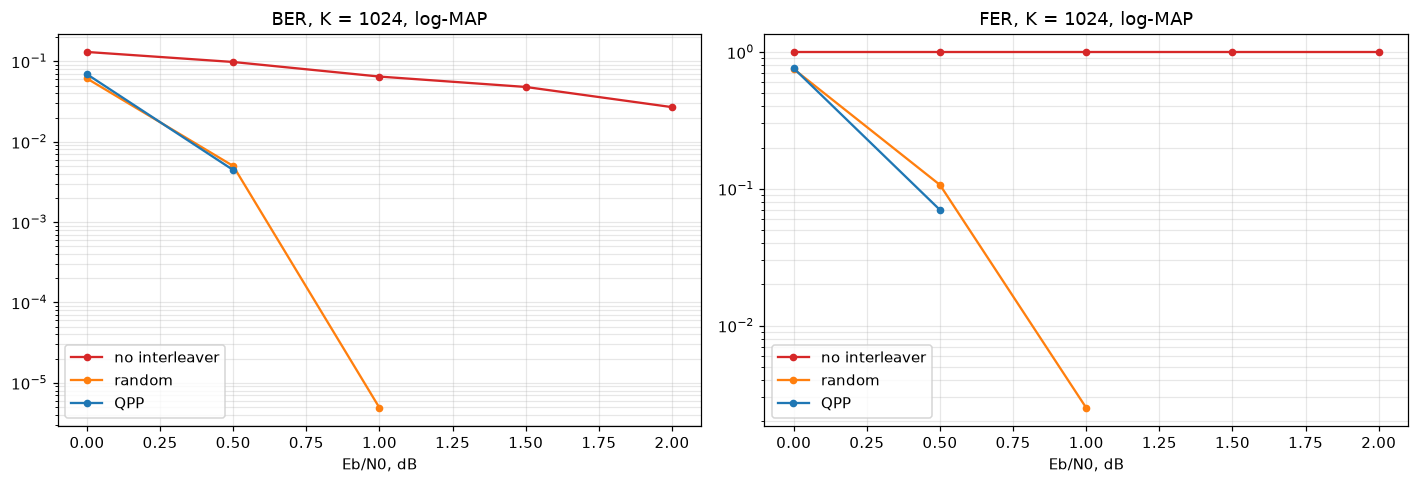

no interleaver : 0.0 dB: FER 1.000  0.5 dB: FER 1.000  1.0 dB: FER 1.000  1.5 dB: FER 1.000  2.0 dB: FER 1.000
random         : 0.0 dB: FER 0.750  0.5 dB: FER 0.107  1.0 dB: FER 0.003  1.5 dB: FER 0.000  2.0 dB: FER 0.000
QPP            : 0.0 dB: FER 0.760  0.5 dB: FER 0.070  1.0 dB: FER 0.000  1.5 dB: FER 0.000  2.0 dB: FER 0.000


In [13]:
eb11 = np.arange(0.0, 2.01, 0.5)
res11 = {name: sim_turbo(eb11, pi=p, max_frames=400)[0] for name, p in pis.items()}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for (name, r_), c_ in zip(res11.items(), ["C3", "C1", "C0"]):
    for a, k in zip(ax, (0, 1)):
        ok = r_[:, k] > 0
        a.semilogy(eb11[ok], r_[ok, k], "o-", color=c_, ms=4, label=name)
for a, t in zip(ax, ("BER", "FER")):
    a.set_xlabel("Eb/N0, dB"); a.set_title(f"{t}, K = {K_TURBO}, log-MAP"); a.legend(); a.grid(which="both", alpha=0.3)
plt.tight_layout(); plt.show()
for name, r_ in res11.items():
    print(f"{name:15s}: " + "  ".join(f"{e:.1f} dB: FER {r[1]:.3f}" for e, r in zip(eb11, r_)))

## 12. Block length
The longer the block, the more room the interleaver has and the closer we get to the asymptote (the EXIT threshold): the waterfall gets steeper and moves left. At $K=40$ there is almost no waterfall; the curve is shallow, like an ordinary convolutional code. An interleaver over 40 bits can't move bits far apart, and the extrinsic information is strongly correlated. LTE uses 188 sizes from 40 to 6144; long transport blocks are cut into segments of up to 6144.

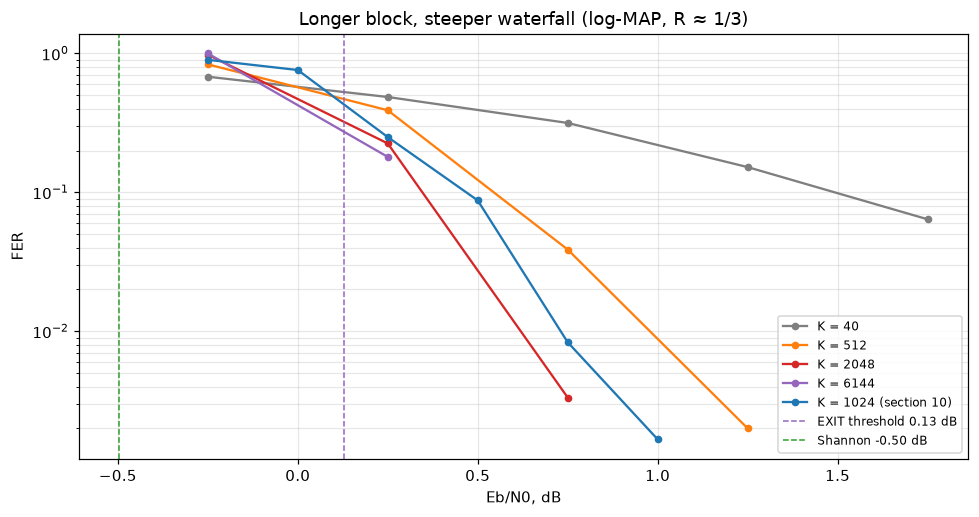

FER: Eb/N0       K=40     K=512    K=2048    K=6144
     -0.25   6.80e-01  8.35e-01  9.80e-01  1.00e+00
      0.25   4.86e-01  3.90e-01  2.25e-01  1.80e-01
      0.75   3.16e-01  3.87e-02  3.33e-03  0.00e+00
      1.25   1.52e-01  2.00e-03  0.00e+00  0.00e+00
      1.75   6.40e-02  0.00e+00  0.00e+00  0.00e+00


In [14]:
lens = [40, 512, 2048, 6144]
eb12 = np.arange(-0.25, 2.01, 0.5)
mf = {40: 4000, 512: 1000, 2048: 300, 6144: 100}
bt = {40: 500, 512: 200, 2048: 100, 6144: 50}
res12 = {K_: sim_turbo(eb12, K=K_, max_frames=mf[K_], batch=bt[K_])[0] for K_ in lens}
fig, a = plt.subplots(figsize=(9, 4.8))
for K_, c_ in zip(lens, ["C7", "C1", "C3", "C4"]):
    r_ = res12[K_]; ok = r_[:, 1] > 0
    a.semilogy(eb12[ok], r_[ok, 1], "o-", color=c_, ms=4, label=f"K = {K_}")
ok = r_log[:, 1] > 0
a.semilogy(eb10[ok], r_log[ok, 1], "o-", color="C0", ms=4, label=f"K = {K_TURBO} (section 10)")
a.axvline(TH_T, color="C4", ls="--", lw=1, label=f"EXIT threshold {TH_T:.2f} dB"); a.axvline(SH3, color="C2", ls="--", lw=1, label=f"Shannon {SH3:.2f} dB")
a.set_xlabel("Eb/N0, dB"); a.set_ylabel("FER"); a.legend(fontsize=8); a.grid(which="both", alpha=0.3); a.set_title("Longer block, steeper waterfall (log-MAP, R ≈ 1/3)")
plt.tight_layout(); plt.show()
print("FER: Eb/N0 " + "".join(f"{f'K={K_}':>10s}" for K_ in lens))
for j, e in enumerate(eb12): print(f"     {e:5.2f} " + "".join(f"{res12[K_][j, 1]:10.2e}" for K_ in lens))

## 13. Turbo vs. LDPC at the same $R$ and $n$
For a fair comparison with the regular (3,6) LDPC code from the LDPC notebook ($R\approx1/2$, $n=1008$, sum-product, 50 iterations), we take $K=512$ and **puncture** every other parity bit (the decoder gets LLR = 0 in their place): $n=1036$, $R\approx0.494$. LTE does the same thing with rate matching through a circular buffer.

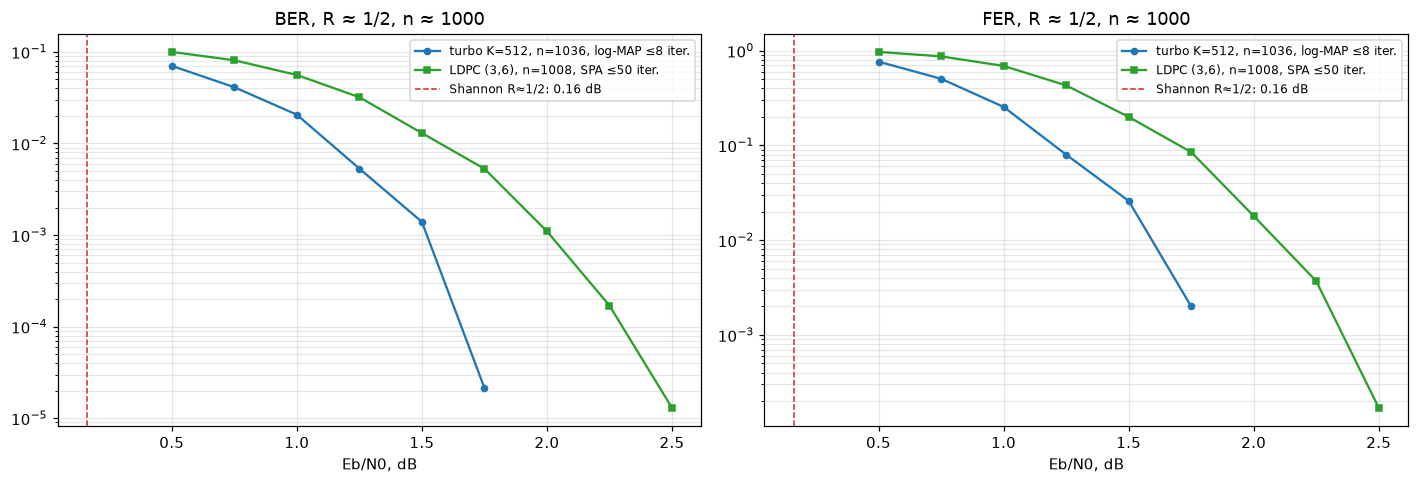

Eb/N0 0.50 dB: turbo BER 7.0e-02 FER 0.765 (200 frames) | LDPC (3,6) BER 1.0e-01 FER 9.7e-01
Eb/N0 0.75 dB: turbo BER 4.1e-02 FER 0.505 (200 frames) | LDPC (3,6) BER 8.1e-02 FER 8.7e-01
Eb/N0 1.00 dB: turbo BER 2.1e-02 FER 0.255 (200 frames) | LDPC (3,6) BER 5.6e-02 FER 6.9e-01
Eb/N0 1.25 dB: turbo BER 5.3e-03 FER 0.080 (400 frames) | LDPC (3,6) BER 3.2e-02 FER 4.3e-01
Eb/N0 1.50 dB: turbo BER 1.4e-03 FER 0.026 (1000 frames) | LDPC (3,6) BER 1.3e-02 FER 2.0e-01
Eb/N0 1.75 dB: turbo BER 2.1e-05 FER 0.002 (1000 frames) | LDPC (3,6) BER 5.3e-03 FER 8.5e-02
Eb/N0 2.00 dB: turbo BER 0.0e+00 FER 0.000 (1000 frames) | LDPC (3,6) BER 1.1e-03 FER 1.8e-02
Eb/N0 2.25 dB: turbo BER 0.0e+00 FER 0.000 (1000 frames) | LDPC (3,6) BER 1.7e-04 FER 3.7e-03
Eb/N0 2.50 dB: turbo BER 0.0e+00 FER 0.000 (1000 frames) | LDPC (3,6) BER 1.3e-05 FER 1.7e-04


In [15]:
K13 = 512
pm = puncture_half(K13)
eb13 = np.arange(0.5, 2.51, 0.25)
r13, _ = sim_turbo(eb13, K=K13, mask=pm, max_frames=1000, batch=200)
ldpc_ber = {0.5: 1.0e-01, 0.75: 8.1e-02, 1.0: 5.6e-02, 1.25: 3.2e-02, 1.5: 1.3e-02, 1.75: 5.3e-03, 2.0: 1.1e-03, 2.25: 1.7e-04, 2.5: 1.3e-05}
ldpc_fer = {0.5: 9.7e-01, 0.75: 8.7e-01, 1.0: 6.9e-01, 1.25: 4.3e-01, 1.5: 2.0e-01, 1.75: 8.5e-02, 2.0: 1.8e-02, 2.25: 3.7e-03, 2.5: 1.7e-04}
SH2 = biawgn_limit(K13 / pm.sum())                # the tables come from ldpc_sim_en.ipynb (section 15)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, k, d, t in [(ax[0], 0, ldpc_ber, "BER"), (ax[1], 1, ldpc_fer, "FER")]:
    ok = r13[:, k] > 0
    a.semilogy(eb13[ok], r13[ok, k], "C0o-", ms=4, label=f"turbo K={K13}, n={pm.sum()}, log-MAP ≤{ITERS} iter.")
    a.semilogy(list(d), list(d.values()), "C2s-", ms=4, label="LDPC (3,6), n=1008, SPA ≤50 iter.")
    a.axvline(SH2, color="C3", ls="--", lw=1, label=f"Shannon R≈1/2: {SH2:.2f} dB")
    a.set_xlabel("Eb/N0, dB"); a.set_title(f"{t}, R ≈ 1/2, n ≈ 1000"); a.legend(fontsize=8); a.grid(which="both", alpha=0.3)
plt.tight_layout(); plt.show()
for e, r in zip(eb13, r13):
    print(f"Eb/N0 {e:.2f} dB: turbo BER {r[0]:.1e} FER {r[1]:.3f} ({int(r[3])} frames) | LDPC (3,6) BER {ldpc_ber.get(round(e, 2), np.nan):.1e} FER {ldpc_fer.get(round(e, 2), np.nan):.1e}")

## Comparison with LDPC and LTE
| | Turbo code (LTE) | LDPC (5G NR, Wi-Fi) |
|---|---|---|
| Structure | two 8-state RSCs + an interleaver | sparse $H$, Tanner graph |
| Decoder "node" | BCJR on the trellis of a whole code | a parity check over $d_c$ bits |
| Iterations | 6–8 (each is 2 BCJRs) | 10–50 |
| Parallelism | BCJR is sequential along the trellis; windows + contention-free QPP | all checks (or a layer) at once |
| Distance to Shannon ($n\sim1000$) | excellent even with a simple encoder | regular (3,6) is worse; irregular codes beat turbo |
| Error floor | noticeable (low-weight codewords through the interleaver) | lower with a good graph |
| Rate flexibility | puncturing from $R=1/3$ | base graph + puncturing/extension |

In the LTE notebook (sections 7–8) the turbo code works inside an OFDM chain on a frequency-selective channel; here we looked at how it works inside. Both codes are instances of one idea: **a strong code built from simple components + iterative exchange of extrinsic LLRs**. 5G moved to LDPC mainly for decoder throughput (tens of Gbit/s), because the turbo code's BCJR trellis is sequential.

## Things to try
- `EBN0_DB = 0.0`: below the threshold. In section 9 the tunnel is closed, in section 8 most frames get stuck, and the trajectory runs into the point where the curves cross
- `SCALE_ML = 1.0` in section 10: max-log without scaling shows how many tenths of a dB the 0.7 factor buys back
- `ITERS = 2`: in section 10 (right), after 1–2 iterations the turbo code is not much better than a single convolutional code
- in section 6, 30 iterations instead of 12: the "echo" never converges, no matter how long you iterate
- in section 3, `range(7, 50, 7)` → `range(1, 50)`: all weight-2 inputs up to distance 49 (slow). The QPP minimum weight doesn't change, since inputs with $d\not\equiv0\pmod 7$ give a heavy $\mathbf z_1$
- in section 11, `max_frames=5000` and `eb11` up to 2.5 dB: the floor of the random interleaver starts to show
- `K_TURBO = 6144`: an even steeper waterfall, the same EXIT threshold (about 6× slower)